In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [110]:
import importlib
import functions_jules
importlib.reload(functions_jules)

from functions_jules import *


**Section 1 : Data and Processing**


In [89]:
data = process_excel('data.xlsx')


/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/pandas/core/indexes/base.py:7616: FutureWarning:

Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.



In [22]:
print(data[['SPX Index']].dropna().index)

DatetimeIndex(['1990-01-02', '1990-01-03', '1990-01-04', '1990-01-05',
               '1990-01-08', '1990-01-09', '1990-01-10', '1990-01-11',
               '1990-01-12', '1990-01-16',
               ...
               '2025-04-10', '2025-04-11', '2025-04-14', '2025-04-15',
               '2025-04-16', '2025-04-17', '2025-04-21', '2025-04-22',
               '2025-04-23',        'NaT'],
              dtype='datetime64[ns]', name='Dates', length=8832, freq=None)


In [ ]:
#Create processing dictionnary with correct number of diff and log


int_order = get_integration_order(data)
preprocessing_dict1 = {
    col : ['diff']*k for col, k in int_order.items()  #Can add ['log'], but have to put log(data)
    }
preprocessing_dict1['VIX'] = []

print(preprocessing_dict1)

SPX Index
Lag 1 rejeté : p-val = 0.0000
Lag 2 rejeté : p-val = 0.0000
Lag 3 rejeté : p-val = 0.0000
Lag 4 rejeté : p-val = 0.0002
Lag 5 rejeté : p-val = 0.0425
Lag 6 rejeté : p-val = 0.0000
Lag 7 rejeté : p-val = 0.0000
Lag 8 rejeté : p-val = 0.0000
Lag 9 rejeté : p-val = 0.0002
Lag 10 accepté : p-val = 0.9932

==== Résultat du test ADF ====
Statistique ADF     : 1.4356
P-valeur            : 0.9973
Retards utilisés    : 10
Lag 1 rejeté : p-val = 0.0125
Lag 2 rejeté : p-val = 0.0013
Lag 3 rejeté : p-val = 0.0001
Lag 4 accepté : p-val = 0.9986

==== Résultat du test ADF ====
Statistique ADF     : -44.5016
P-valeur            : 0.0000
Retards utilisés    : 4
CAC Index
Lag 1 accepté : p-val = 0.3864

==== Résultat du test ADF ====
Statistique ADF     : -1.2576
P-valeur            : 0.6483
Retards utilisés    : 1
Lag 1 accepté : p-val = 0.7890

==== Résultat du test ADF ====
Statistique ADF     : -67.3039
P-valeur            : 0.0000
Retards utilisés    : 1
DAX Index
Lag 1 rejeté : p-val = 

### **Subsection: Target – SPX with All Possible Exogenous Variables**

We use the `calibrate_and_store` function to fit the MS-ARCH-X model with the SPX index as the target variable and all other indices as potential exogenous indicators. The fitting procedure uses the following iteration thresholds: `n_iter_HMM = 1000`, `niterMS = 1000`, and `niterX = 100`.

To prepare the data, we generate a preprocessing dictionary using the `get_integration_order(data)` function. This determines the number of differences required to render each time series stationary. Before differencing, we apply a logarithmic transformation to all indices to ensure the additivity of returns — except for the VIX index, which is kept in its raw form (no log, no differencing) due to its interpretive properties.

After fitting the model, we extract the output from `.pkl` files to visualize and analyze the volatility dynamics estimated for each model. These volatilities are plotted individually and then overlaid with the VIX for comparison. All resulting figures are exported as `.pdf` files for documentation and review.


In [ ]:

#Results are stored in SPX_VIX_GOOD_RUN
#For exogenous squared and not abs, results in SPX_VIX_GOOD_RUN_SQUARE


niter_HMM = 1000
niter_MS = 1000
niter_X = 100

threshold = 8000  # min number of valid (non-NaN) values
good_indicators = [
    [col] for col in data.columns 
    if col != 'SPX Index' and data[col].notna().sum() > threshold
]

store = calibrate_and_store(
    data=data,
    targets=['SPX Index'],
    indicators=good_indicators,  # filtered as above
    d=2, q=1,
    niter_HMM=1000,
    niter_MS=1000,
    niter_X=100,
    folder='SPX_VIX_GOOD',
    preprocessing_dict = preprocessing_dict1
)

"""
if you call :
store = calibrate_and_store(
    data=data,
    targets=['SPX Index'],
    indicators=[['VIX Index'], ['Oil Index']],
    d=2, q=1,
    niter_HMM=100, niter_MS=100, niter_X=50,
    folder='ExampleRun',
    preprocessing_dict=None
)

You return :


store = {
  'SPX Index': {
    'No Exogenous': {
        'eps': np.array([...]),
        'dates': pd.DatetimeIndex([...]),
        'target': 'SPX Index',
        'indicator': 'No Exogenous',
        'initial_params': {...},
        'result': [...],  # list of intermediate parameter sets from EM
        'final_result': {...},  # final parameter dict
        'states sequence': np.array([...]),
    },

    'VIX Index': {
        'eps': np.array([...]),
        'dates': pd.DatetimeIndex([...]),
        'target': 'SPX Index',
        'indicator': 'VIX Index',
        'initial_params': {...},
        'result': [...],
        'final_result': {
            'sigma²': np.array([...]),
            'mu': np.array([...]),
            'beta': np.array([...]),
            'log-likelihood': ...,
            'mean log-likelihood': ...,
            'exogen_transition': np.array([...]),
            'exogen_additive': np.array([...]),
        },
        'states sequence': np.array([...]),
    },

    'Oil Index': {
        ...
    }
  }
}


store['SPX Index']['No Exogenous']['final_result']['sigma²']  # variance path
store['SPX Index']['VIX Index']['final_result']['mu']          # mu coefficients
store['SPX Index']['VIX Index']['states sequence']             # inferred regime path
store['SPX Index']['VIX Index']['dates']                       # aligned dates

"""

In [90]:
# Load all .pkl result files from calibration


stored_data = load_stored_results('SPX_VIX_GOOD_RUN')

# Compute sigma^2_t for each model
Sigma_backtest = compute_sigma_backtest(stored_data, targets=['SPX Index'])

print(Sigma_backtest)
print(stored_data)

100%|██████████| 1/1 [00:35<00:00, 35.52s/it]


defaultdict(<function compute_sigma_backtest.<locals>.<lambda> at 0x13c9b7f70>, {'SPX Index': {'RTY Index': array([2.01634526, 1.97827672, 2.01328749, ..., 2.63315905, 2.58579903,
       2.23279049]), 'GTDEM2Y Govt': array([0.62374176, 0.68973512, 1.08677167, ..., 1.62431619, 1.70992562,
       1.09434573]), 'NKY Index': array([1.66588273, 1.64650378, 1.71427882, ..., 2.42399256, 2.48913633,
       1.98445035]), 'CO1 Comdty': array([1.66187542, 1.62324494, 1.70429577, ..., 2.61742865, 2.67955105,
       2.09894313]), 'SXXP Index': array([1.68790302, 1.63898713, 1.68247982, ..., 2.43289302, 2.49396643,
       1.9838363 ]), 'GTDEM10Y Govt': array([2.35204804, 2.490205  , 2.25975047, ..., 3.29576833, 3.38960515,
       2.75330445]), 'No Exogenous': array([2.42397466, 2.38855562, 2.45036557, ..., 3.36329689, 3.44751617,
       2.84096294]), 'USGG2YR Index': array([0.53313959, 0.54236902, 0.65532369, ..., 1.52517918, 1.60192585,
       1.00330164]), 'USGG10YR Index': array([2.34584138, 2.29

In [93]:
#All plots of volatility from models superposed with the VIX

plot_model_vs_vix(
    data=data,
    stored_data=stored_data,
    sigma_dict=Sigma_backtest,
    target='SPX Index',
    comparison_series='VIX Index'
)


❌ Could not extract VIX for 'No Exogenous': "[Timestamp('2025-04-24 00:00:00')] not in index"


## Section: Regime-Based ARCH and GARCH Modeling on SPX

In this section, we investigate volatility behavior across economic regimes by applying **ARCH(1)** and **GARCH(1,1)** models to segments of the S&P 500 index data, labeled according to pre-defined regime periods: **Stability**, **Crisis**, and **Recovery**. The objective is to understand how volatility structure varies across macroeconomic conditions.

---

### 1. **Data Loading and Regime Labeling**

We used the following functions to load and process the data:

- `load_selected_columns(filepath, target, indicators)`  
  Extracts relevant columns (target + indicators) from an Excel file and formats the datetime index.

- `add_regime_labels(df, output_filename)`  
  Assigns each date to one of 15 historical regimes and saves the updated DataFrame to Excel.

The resulting dataset `SPX_with_regimes.xlsx` includes:  
- A `Date` column  
- `SPX Index`, `VIX Index`, and other indicators  
- A new `Regime` column for each observation

---

### 2. **Return Computation and Initial Visualization**

We used:
- `plot_returns_by_regime(filepath, index_name)`  
  to plot raw return paths by regime  
- `plot_log_returns_by_regime(filepath, index_name)`  
  to visualize **log returns**, which are additive and better suited for volatility comparison.

These plots revealed sharp spikes during Crisis regimes and smoother, flatter behavior during Stability.

---

### 3. **ARCH(1) Estimation per Regime**

We applied an ARCH(1) model on each regime segment using:

- `fit_arch1_per_regime(filepath, index_name, regime_periods)`  
  - Computes log returns: `log(P_t) - log(P_{t-1})`  
  - Fits an ARCH(1) model on each regime window  
  - Returns a `results_df` with:
    - `mu`: mean return
    - `alpha0`: baseline variance
    - `alpha1`: volatility clustering

We then visualized the parameter distributions:

- `analyze_arch_parameters_by_regime(results_df)`  
  - Computes mean and std of each parameter by regime  
  - Plots boxplots for `mu`, `alpha0`, and `alpha1` using seaborn

---

### 4. **ARCH(1) Volatility Path Plotting**

To visualize ARCH volatility per segment:

- `plot_arch_volatility_paths_by_regime(filepath, index_name, regime_periods)`  
  - Computes % returns
  - Fits ARCH(1) model per regime
  - Plots conditional volatility over time, one subplot per regime segment

This allows us to observe how ARCH volatility responds within each regime, even though ARCH models assume conditional independence across time.

---

### 5. **GARCH(1,1) Estimation and Analysis**

We then moved to a more flexible volatility structure:

- `fit_garch_by_regime(filepath, index_name, regime_periods)`  
  - Same logic as the ARCH model, but using GARCH(1,1)  
  - Returns `mu`, `omega`, `alpha1`, `beta1`, and `persistence = alpha1 + beta1`

- `plot_garch_parameter_distributions(results_df)`  
  - Boxplots for all GARCH parameters by regime  
  - Highlights differences in volatility memory and shock response across conditions

---

### 6. **GARCH Volatility Path Visualization**

To display GARCH conditional volatilities per regime:

- `plot_garch_volatility_paths_by_regime(filepath, index_name, regime_periods)`  
  - Same process as ARCH plotting, but with GARCH(1,1) models  
  - Returns volatility series for each segment  
  ⚠️ **Note:** This visualization is for illustration only. GARCH models assume **continuous time dependence**, so fitting them per regime violates their structure.

---

### 7. **Manual Debugging of Pathologies**

To verify strange behavior (e.g., `alpha1 = 0`), we ran a standalone block:

- Compared **ARCH(1)** vs **GARCH(1,1)** on suspicious regimes (`2022-01-01 to 2022-10-12`, etc.)
- Used raw SPX prices to recompute returns inside the loop
- Printed `.params` to verify model convergence and structure

This confirmed that zero `alpha1` can occur naturally in low-volatility or low-persistence segments.

---

### ✅ Summary of Key Tools Used

- **ARCH/GARCH models** from `arch` package
- **Matplotlib** and **Seaborn** for visualization
- **Pandas** and **Numpy** for data management
- All model fitting handled with:
  ```python
  arch_model(returns, vol='ARCH' or 'GARCH', p=1, q=1, ...)
  ```

This section sets the foundation for **regime-switching volatility models** like MS-ARCH-X, by confirming that volatility dynamics differ structurally across macroeconomic phases.

---

### 🔍 Analysis

While this section provides valuable insights into how volatility structures change across regimes, the **sample size per regime segment is often limited**, especially for short Crisis periods. This results in **unstable estimates** and **non-conclusive boxplots**, particularly for `alpha1` and `beta1`.

We will revisit this analysis in a later section, where we apply the same modeling strategy to **S&P 500 sub-indices** (e.g., Tech, Healthcare, Financials). These cross-sectional series will provide **multiple realizations per regime**, allowing for more reliable statistical comparisons and a stronger validation of the need for a regime-switching model like MS-ARCH-X.


In [ ]:
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]


In [ ]:
target = 'SPX Index'
indicators = ['VIX Index', 'CAC Index']
input_file = 'data.xlsx'
output_file = 'SPX_with_regimes.xlsx'

df = load_selected_columns(input_file, target, indicators)
df = add_regime_labels(df, output_file)

In [ ]:
pio.renderers.default = "notebook"

plot_returns_by_regime("SPX_with_regimes.xlsx", index_name='SPX Index')


In [ ]:
plot_log_returns_by_regime("SPX_with_regimes.xlsx", index_name='SPX Index')

In [108]:

arch_results_df = fit_arch1_per_regime("SPX_with_regimes.xlsx", index_name='SPX Index', regime_periods=regime_periods)

✅ Fitted Stability — alpha0: 0.6823, alpha1: 0.1944
✅ Fitted Crisis — alpha0: 1.7177, alpha1: 0.1716
✅ Fitted Recovery — alpha0: 1.0546, alpha1: 0.2022
✅ Fitted Stability — alpha0: 0.4990, alpha1: 0.0402
✅ Fitted Crisis — alpha0: 4.7385, alpha1: 0.2275
✅ Fitted Recovery — alpha0: 1.4599, alpha1: 0.0000
✅ Fitted Stability — alpha0: 0.6109, alpha1: 0.2538
⚠️ Skipping Crisis (2020-02-18–2020-03-24) — too few returns: 26
✅ Fitted Recovery — alpha0: 0.8333, alpha1: 0.6759
✅ Fitted Stability — alpha0: 0.6093, alpha1: 0.2424
✅ Fitted Crisis — alpha0: 2.3170, alpha1: 0.0000
✅ Fitted Recovery — alpha0: 0.9035, alpha1: 0.2332
✅ Fitted Stability — alpha0: 0.5612, alpha1: 0.1025
⚠️ Skipping Stability (2025-01-01–2025-02-20) — too few returns: 34
⚠️ Skipping Crisis (2025-02-20–2025-04-07) — too few returns: 33
⚠️ Skipping Recovery (2025-04-08–2025-06-18) — too few returns: 11


In [ ]:
from IPython.display import display
display(arch_results_df)

#results_df.to_excel(DATA / "ARCH_results_by_period.xlsx", index=False)

,Start,End,Regime,mu,alpha0,alpha1
0,1990-01-01,2000-03-31,Stability,0.058642,0.682296,0.194357
1,2000-04-01,2002-09-30,Crisis,-0.075930,1.717747,0.171569
2,2002-10-01,2004-03-31,Recovery,0.071472,1.054556,0.202193
3,2004-04-01,2007-10-31,Stability,0.035608,0.498986,0.040215
4,2007-11-01,2009-03-31,Crisis,-0.155036,4.738495,0.227498
5,2009-04-01,2010-12-31,Recovery,0.103655,1.459872,0.000000
6,2011-01-01,2020-02-17,Stability,0.054626,0.610904,0.253826
7,2020-03-25,2021-09-15,Recovery,0.204352,0.833269,0.675927
8,2020-09-16,2021-12-31,Stability,0.091721,0.609290,0.242376
9,2022-01-01,2022-10-12,Crisis,-0.147185,2.316986,0.000000


### ARCH(1) Parameter Analysis by Regime

After fitting an ARCH(1) model to each economic regime period, we analyze the behavior of the estimated parameters:

- **μ (mu)**: Mean return during the regime.
- **α₀ (alpha0)**: Baseline (unconditional) volatility level — represents the long-term average volatility when there are no recent shocks.
- **α₁ (alpha1)**: Volatility clustering coefficient — how strongly today's volatility depends on yesterday's squared return.

We group all results by regime and compute both the **mean** and **standard deviation** of these parameters. Distributions are visualized using boxplots:

- The blue boxes represent the interquartile range (IQR).
- The horizontal bar in each box marks the median.
- Whiskers extend to 1.5× IQR, and any points beyond are considered outliers.

This analysis reveals distinct volatility dynamics across regimes:
- **Crisis** periods show high alpha1 (strong clustering) and higher alpha0.
- **Stability** has low alpha0 and more symmetric, lower spread.
- **Recovery** regimes tend to have intermediate levels of both.


**Limitations** However, we clearly lack points to have any conclusion (only 3 to 4 points per regimes (number of periods corresponding)), therefore we will later on study the same boxplots with aditional sub indices of the SPX to increase our number of points and maybe try concluding something.


mu              alpha0              alpha1          
               mean       std      mean       std      mean       std
Regime                                                               
Crisis    -0.126050  0.043582  2.924409  1.599360  0.133022  0.118546
Recovery   0.135571  0.059441  1.062787  0.280363  0.277821  0.284832
Stability  0.064385  0.022308  0.592535  0.067839  0.166658  0.092467

Sample sizes used in boxplots per regime:
   Crisis: 3 models
   Recovery: 4 models
   Stability: 5 models


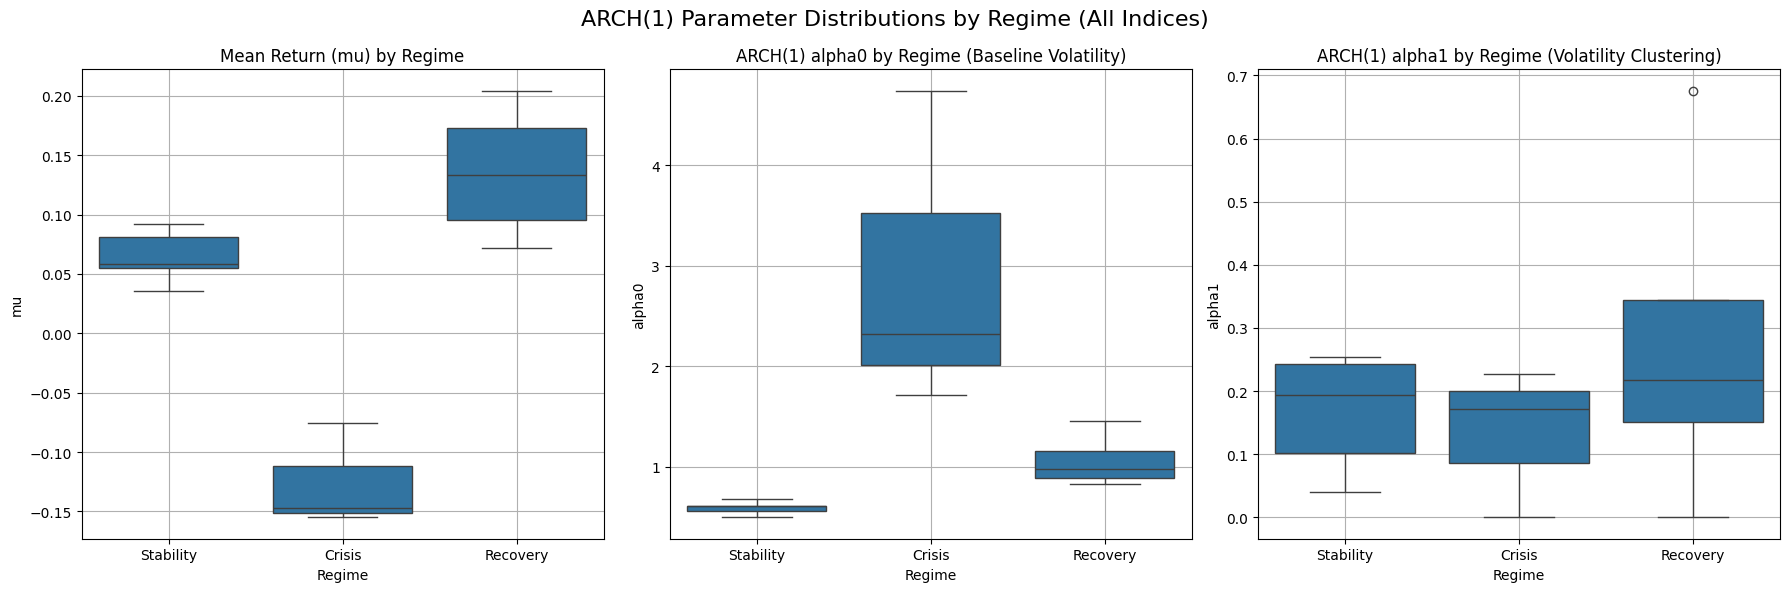

In [ ]:


#arch_results_df = fit_arch1_per_regime("SPX_with_regimes.xlsx", index_name='SPX Index', regime_periods=regime_periods)
group_stats = analyze_arch_parameters_by_regime(arch_results_df)


⚠️ Skipping Crisis 2020-02-18 to 2020-03-24 — too few returns: 26
⚠️ Skipping Stability 2025-01-01 to 2025-02-20 — too few returns: 34
⚠️ Skipping Crisis 2025-02-20 to 2025-04-30 — too few returns: 44


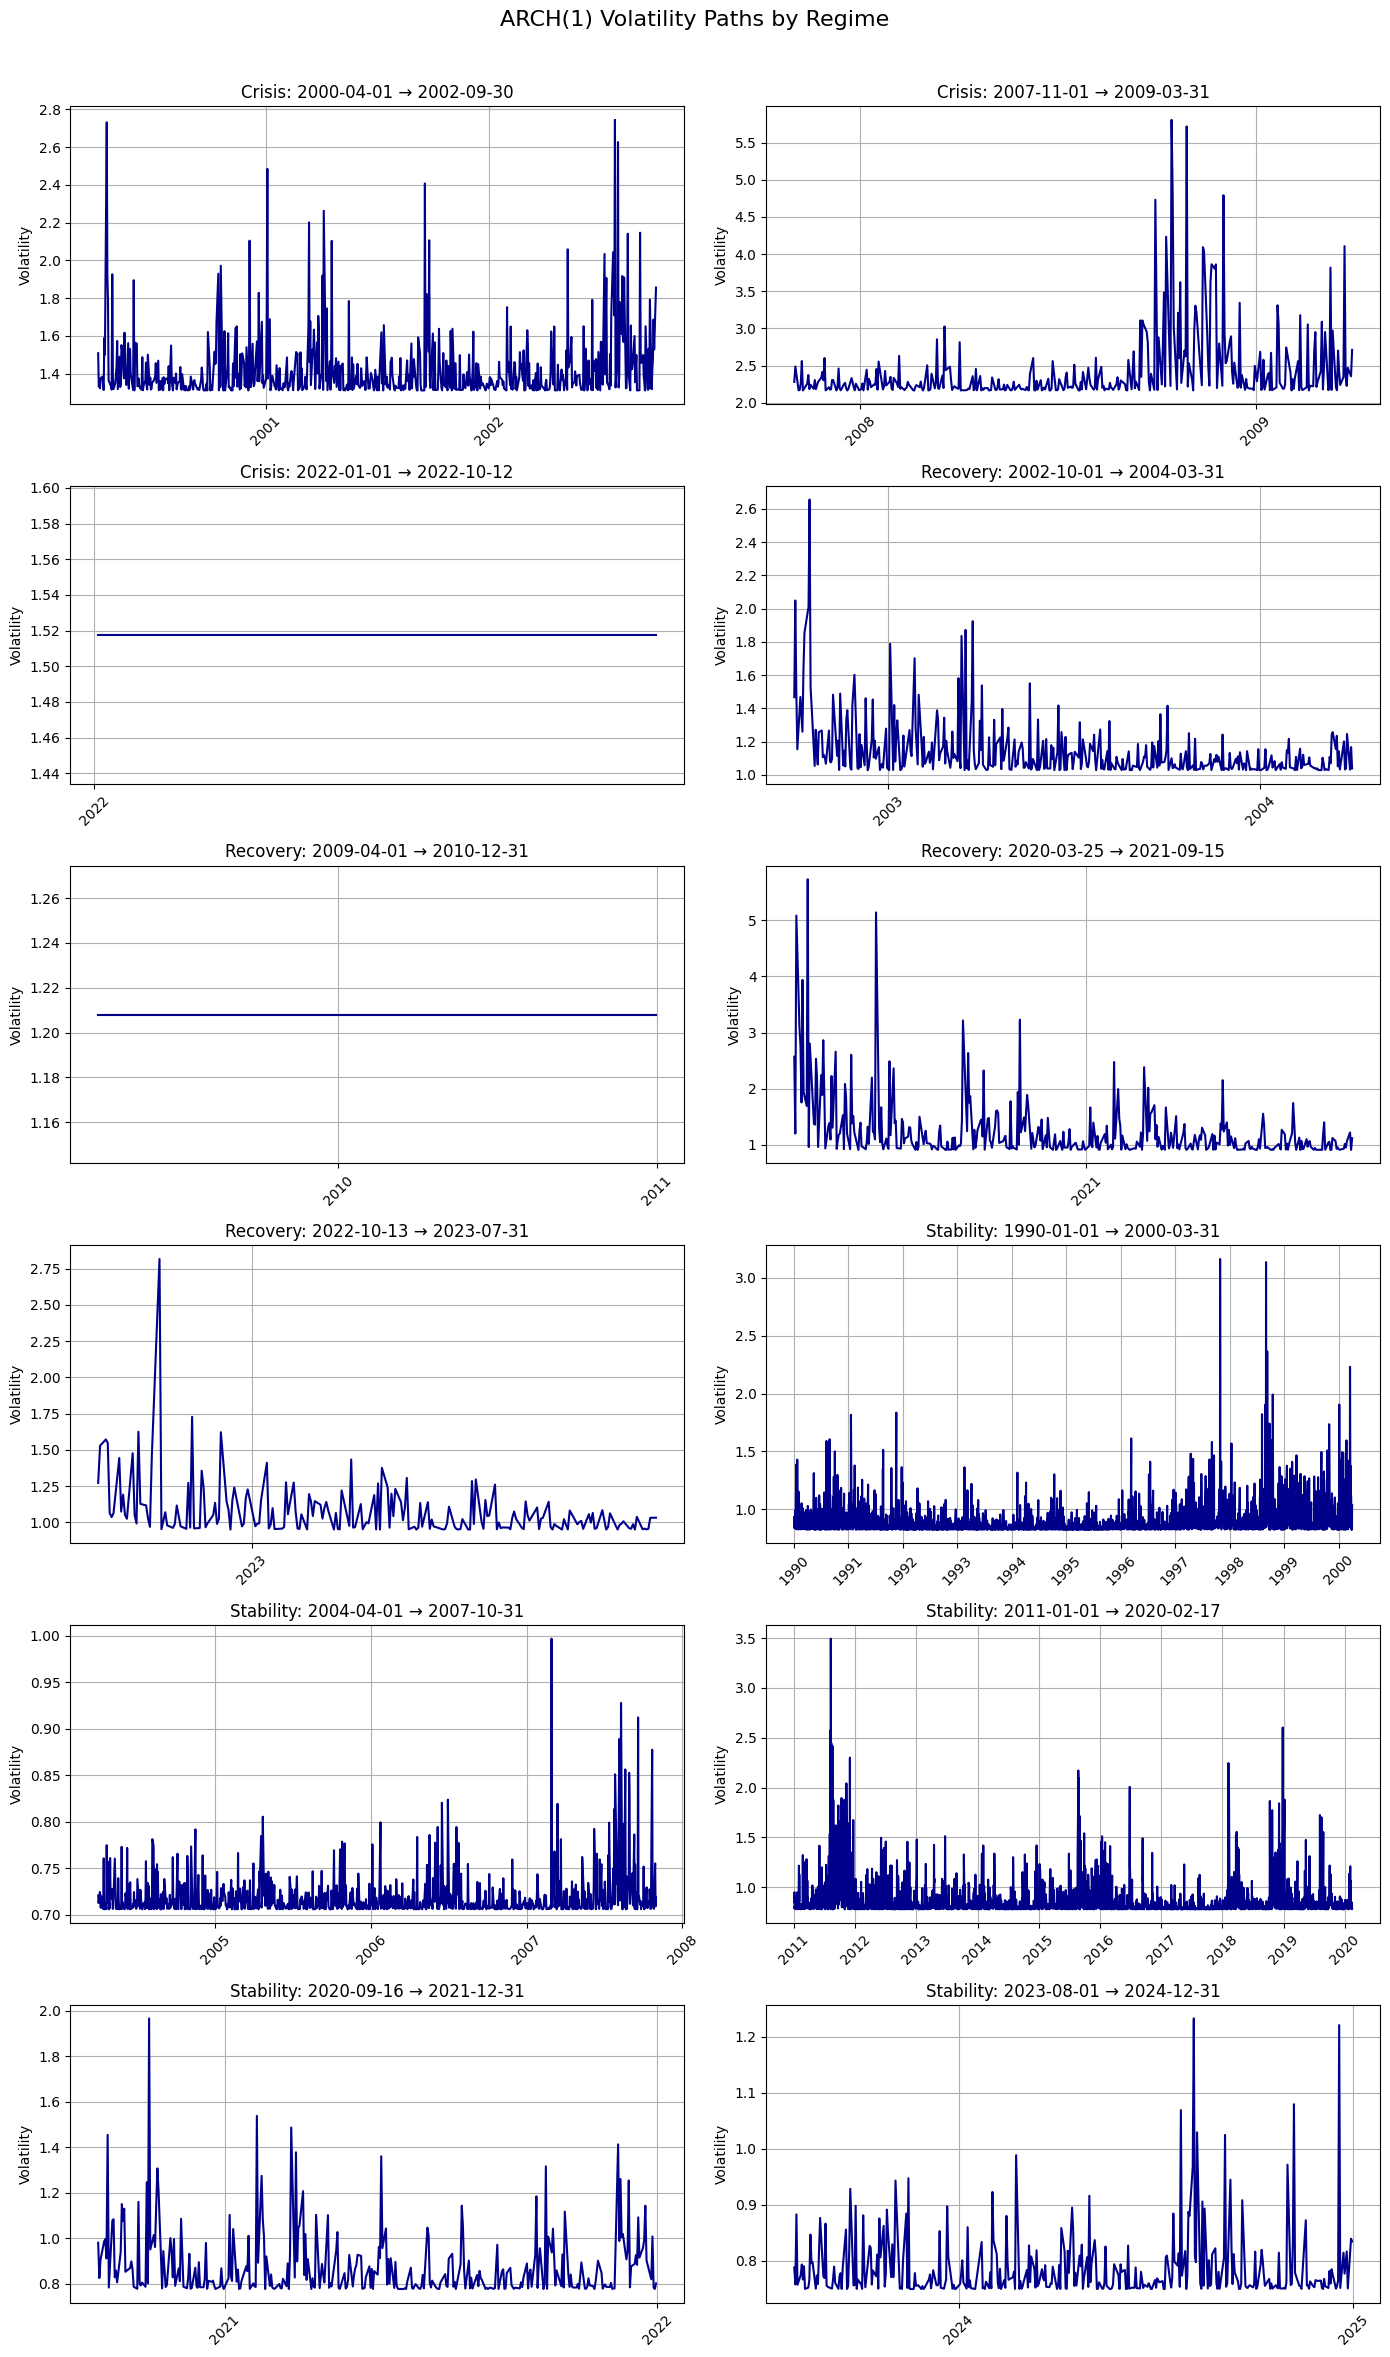

In [ ]:

regime_groups = plot_arch_volatility_paths_by_regime(
    filepath="SPX_with_regimes.xlsx",
    index_name="SPX Index",
    regime_periods=regime_periods
)

In [ ]:
# Load and prepare the data
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

# Define test periods
test_periods = [
    ("2022-01-01", "2022-10-12", "Crisis"),
    ("2009-04-01", "2010-12-31", "Recovery")
]

# Run ARCH and GARCH models on each period
for start, end, label in test_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    price_series = df.loc[mask, 'SPX Index'].copy()
    returns = price_series.pct_change().dropna() * 100  # Compute % return inside loop

    print(f"\n📆 {label} | {start} to {end} | {len(returns)} returns")

    if len(returns) < 100:
        print("⚠️ Not enough data. Skipping...")
        continue

    # ARCH(1)
    am_arch = arch_model(returns, vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False)
    fit_arch = am_arch.fit(disp='off')
    print("ARCH(1) Parameters:")
    print(fit_arch.params)

    # GARCH(1,1)
    am_garch = arch_model(returns, vol='GARCH', p=1, q=1, mean='Constant', dist='normal', rescale=False)
    fit_garch = am_garch.fit(disp='off')
    print("GARCH(1,1) Parameters:")
    print(fit_garch.params)



📆 Crisis | 2022-01-01 to 2022-10-12 | 194 returns
ARCH(1) Parameters:
mu         -0.139505
omega       2.311848
alpha[1]    0.000000
Name: params, dtype: float64
GARCH(1,1) Parameters:
mu         -0.139140
omega       0.135228
alpha[1]    0.028122
beta[1]     0.916541
Name: params, dtype: float64

📆 Recovery | 2009-04-01 to 2010-12-31 | 438 returns
ARCH(1) Parameters:
mu          1.075094e-01
omega       1.457152e+00
alpha[1]    8.692696e-15
Name: params, dtype: float64
GARCH(1,1) Parameters:
mu          0.129884
omega       0.026743
alpha[1]    0.089303
beta[1]     0.889639
Name: params, dtype: float64


### GARCH(1,1) Volatility Paths by Regime

We fitted a separate **GARCH(1,1)** model to each historical regime and plotted the **conditional volatility paths** for each segment.

Steps:
1. Loaded percentage returns from SPX.
2. For each regime period (Crisis, Recovery, Stability), we extracted the corresponding return window.
3. Fitted a GARCH(1,1) model (`p=1`, `q=1`, `mean='Constant'`, `dist='normal'`) to each segment.
4. Stored and plotted the model's estimated conditional volatility over time.

Each subplot visualizes the dynamic behavior of volatility within a specific economic phase, showing how risk evolved internally during that regime.

> ⚠️ **Caveat:** GARCH models assume time-continuous dependency in volatility. By splitting the series into regime-based segments, we violate this assumption. Specifically, **GARCH's lag structure depends on the previous time point**, and cutting time windows removes that dependency chain.  
>
> Therefore, these regime-by-regime GARCH volatility plots are **illustrative but not statistically rigorous**. They help visualize risk patterns within periods, but **should not be used for inference** or comparison across segments.

This justifies the shift to **Markov-switching models**, where regime transitions are modeled formally and allow for time-continuous volatility dynamics across states.


⚠️ Skipping Crisis (2020-02-18–2020-03-24) — too few returns: 26
⚠️ Skipping Stability (2025-01-01–2025-02-20) — too few returns: 34
⚠️ Skipping Crisis (2025-02-20–2025-04-07) — too few returns: 33
⚠️ Skipping Recovery (2025-04-08–2025-06-18) — too few returns: 11


mu               omega              alpha1            \
               mean       std      mean       std      mean       std   
Regime                                                                  
Crisis    -0.099818  0.039363  0.084964  0.038906  0.077025  0.043698   
Recovery   0.115451  0.024001  0.023867  0.028241  0.072806  0.095691   
Stability  0.073257  0.022370  0.056059  0.052710  0.110075  0.078412   

              beta1           persistence            
               mean       std        mean       std  
Regime                                               
Crisis     0.892645  0.024099    0.969670  0.025275  
Recovery   0.905164  0.109911    0.977970  0.014442  
Stability  0.812027  0.129299    0.922102  0.069592

Sample sizes used in boxplots per regime:
   Crisis: 3 models
   Recovery: 4 models
   Stability: 5 models


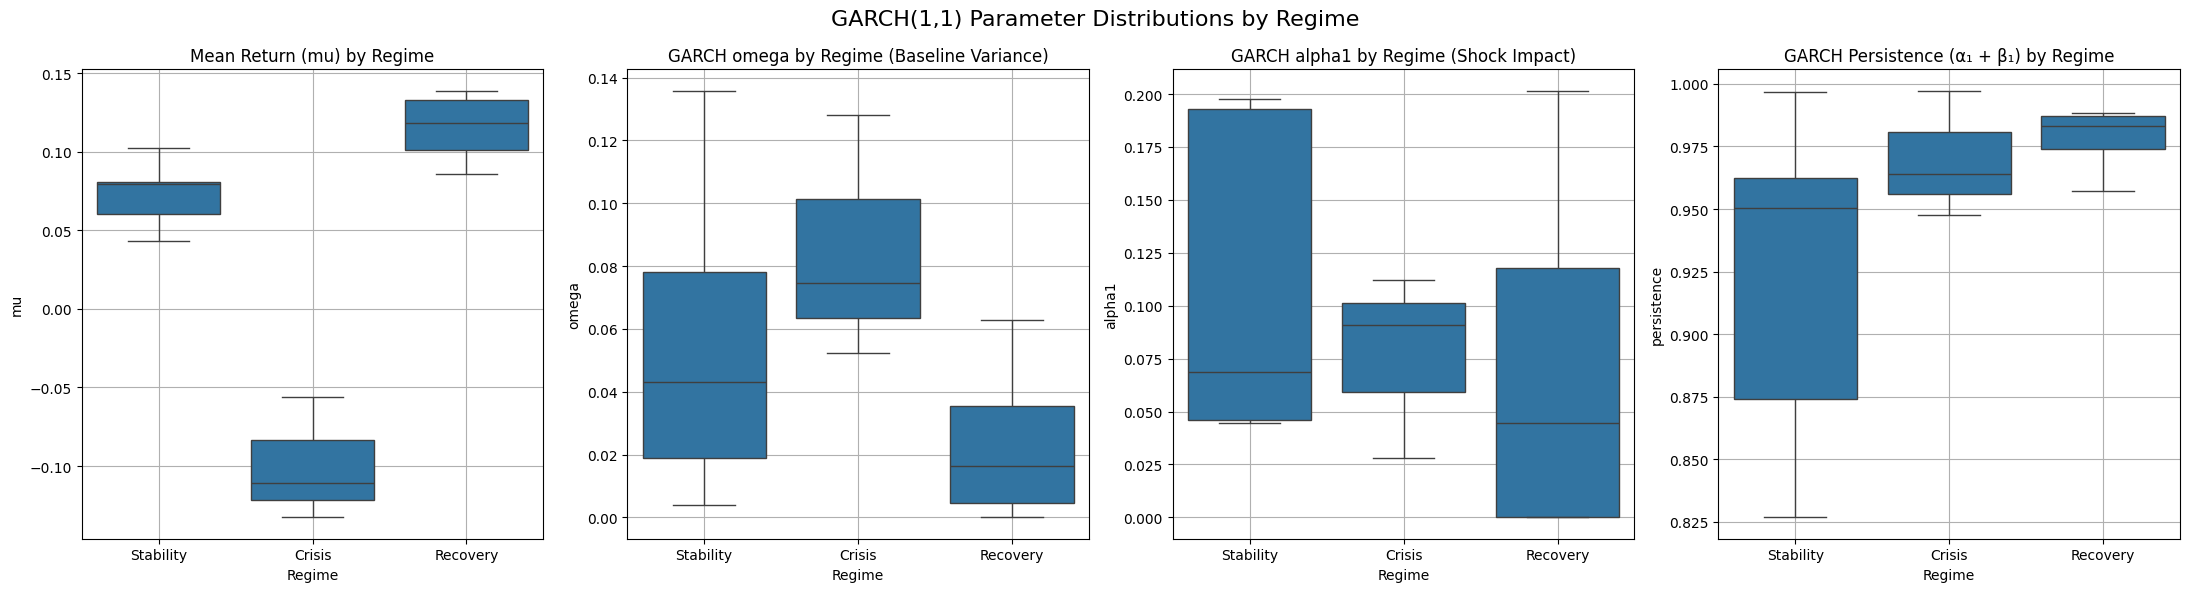

mu               omega              alpha1            \
               mean       std      mean       std      mean       std   
Regime                                                                  
Crisis    -0.099818  0.039363  0.084964  0.038906  0.077025  0.043698   
Recovery   0.115451  0.024001  0.023867  0.028241  0.072806  0.095691   
Stability  0.073257  0.022370  0.056059  0.052710  0.110075  0.078412   

              beta1           persistence            
               mean       std        mean       std  
Regime                                               
Crisis     0.892645  0.024099    0.969670  0.025275  
Recovery   0.905164  0.109911    0.977970  0.014442  
Stability  0.812027  0.129299    0.922102  0.069592

In [112]:
garch_results = fit_garch_by_regime("SPX_with_regimes.xlsx", index_name='SPX Index', regime_periods=regime_periods)
plot_garch_parameter_distributions(garch_results)


⚠️ Skipping Crisis 2020-02-18 to 2020-03-24 — too few returns: 26
⚠️ Skipping Stability 2025-01-01 to 2025-02-20 — too few returns: 34
⚠️ Skipping Crisis 2025-02-20 to 2025-04-30 — too few returns: 44


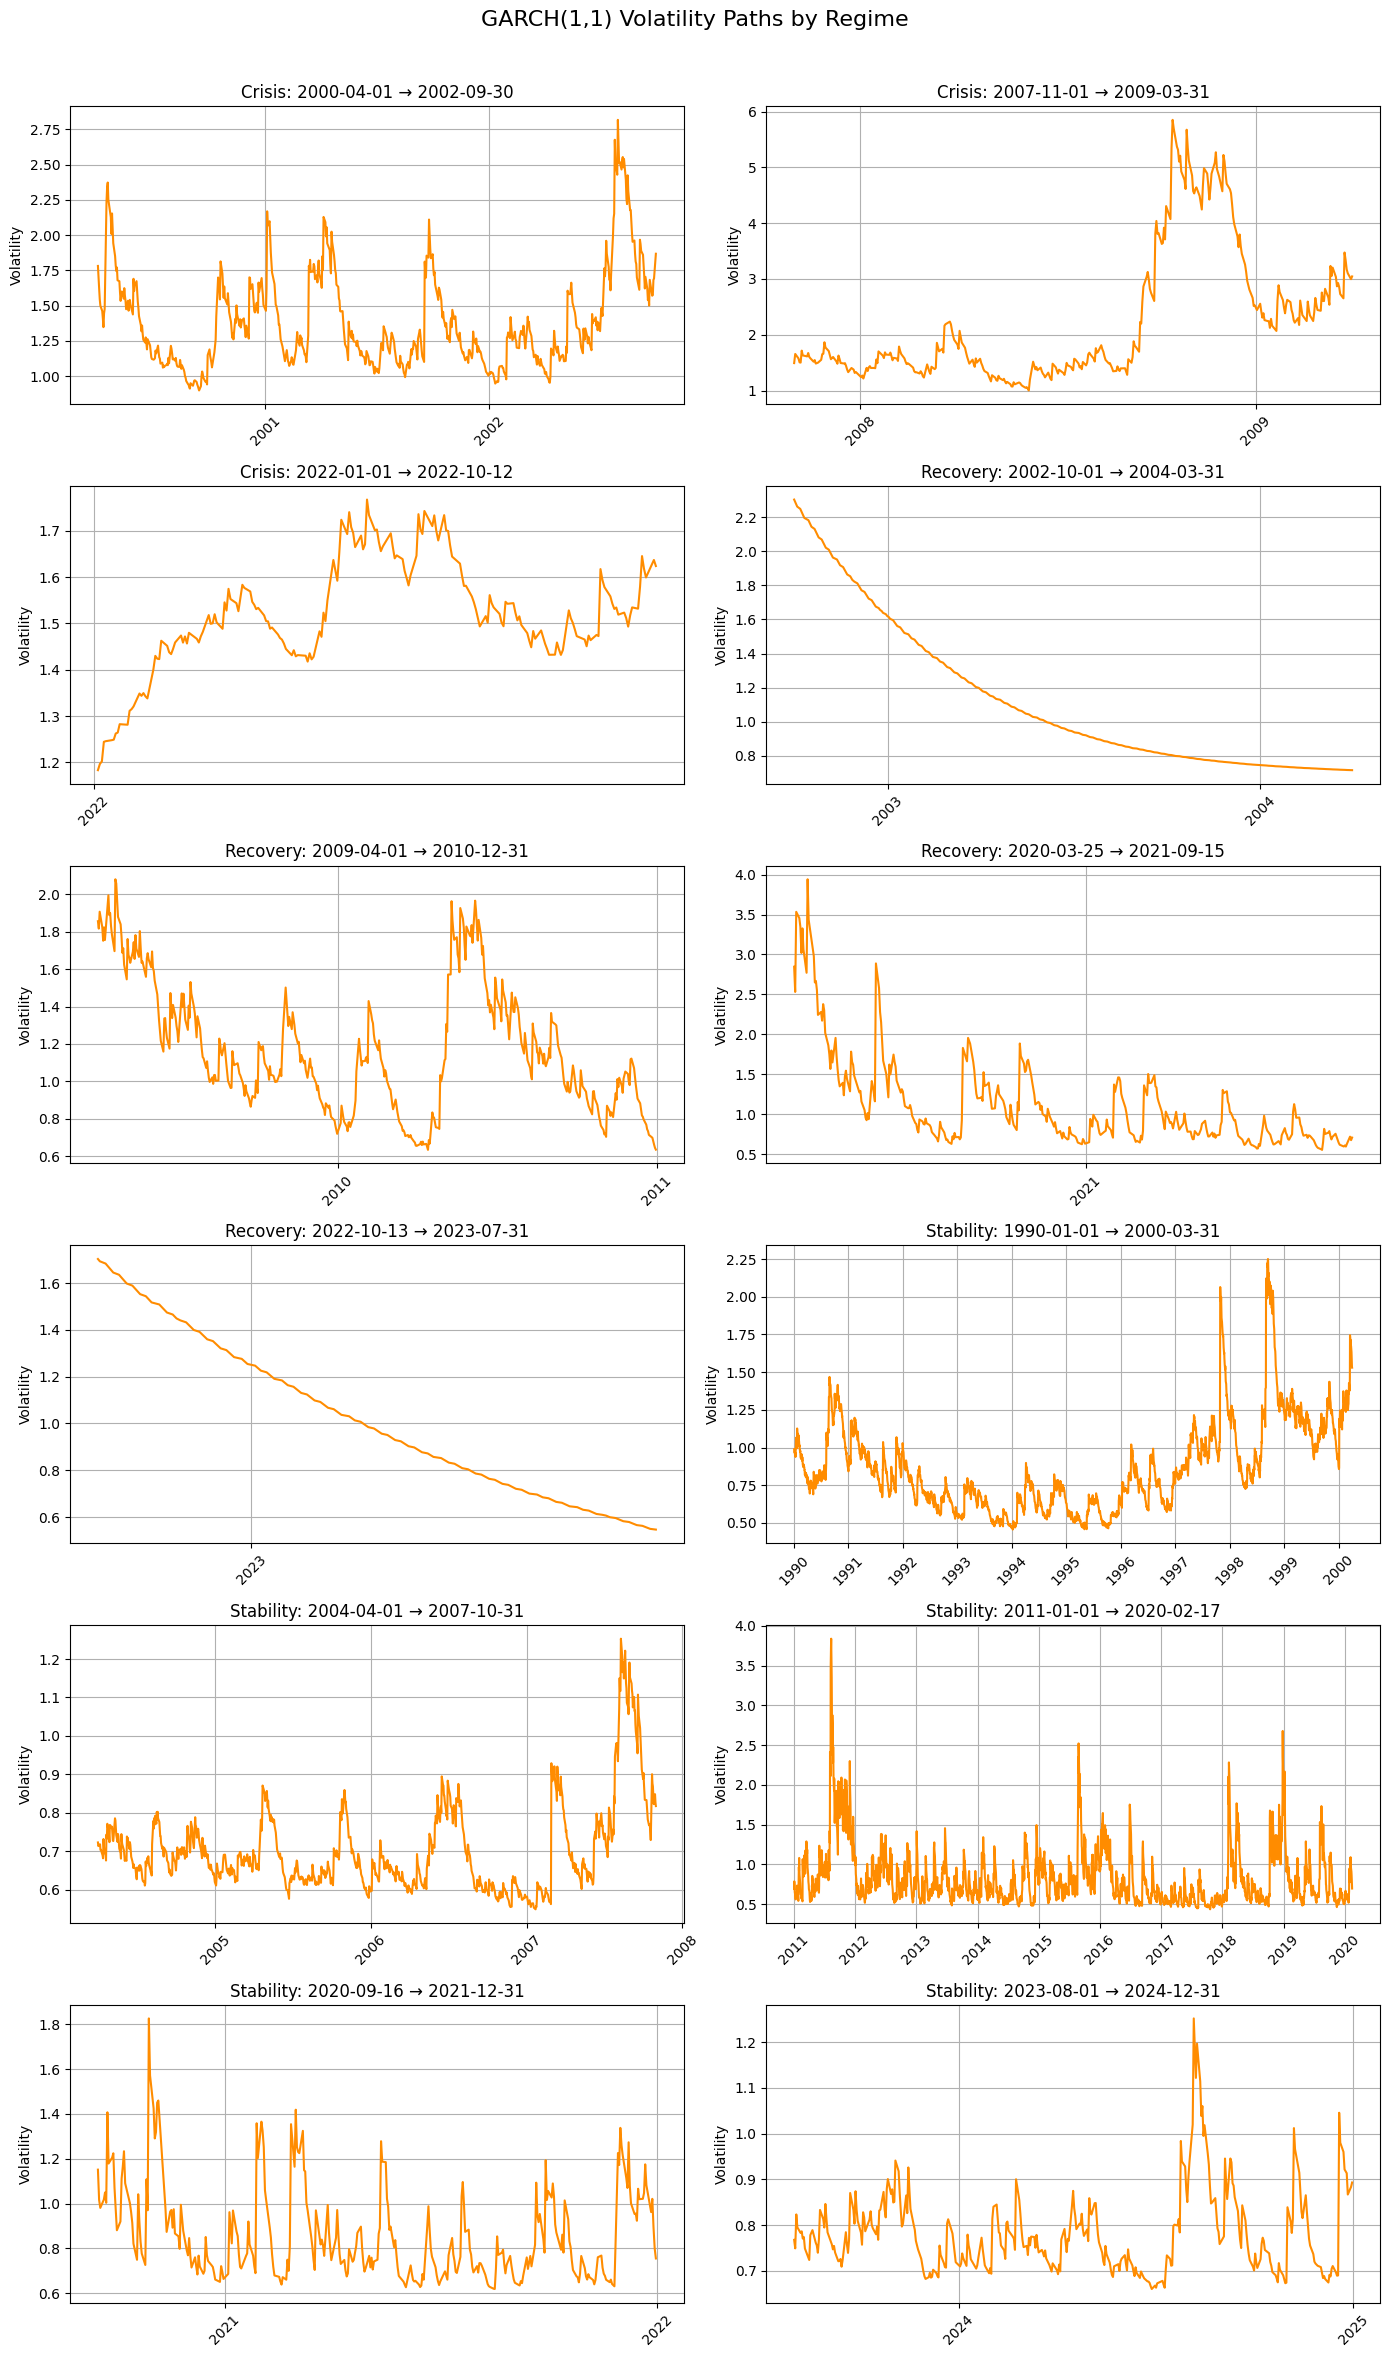

In [ ]:
regime_groups = plot_garch_volatility_paths_by_regime(
    filepath="SPX_with_regimes.xlsx",
    index_name="SPX Index",
    regime_periods=regime_periods
)


## Section: Global GARCH(1,1) Fit and Standardized Residual Analysis by Regime

In this section, we analyze the volatility dynamics of the S&P 500 over the full 1990–2025 sample using a **single GARCH(1,1)** model. The main objective is to examine whether a global volatility model sufficiently captures regime-specific behavior — and whether residuals from this model are consistent with the assumptions of iid standard normal errors.

---

### 1. **Fitting the Global GARCH(1,1)**

We load the SPX data and compute daily percentage returns:

```python
df["Return"] = df["SPX Index"].pct_change() * 100
```

We then fit a GARCH(1,1) model on the **entire return history**, using:

```python
fit = arch_model(..., vol='GARCH', p=1, q=1, mean='Constant', dist='normal')
```

From the fitted model, we extract:
- `Volatility`: the time-varying conditional standard deviation
- `zₜ`: standardized residuals, defined as \( z_t = \frac{r_t - \mu}{\sigma_t} \)

---

### 2. **Volatility Visualization**

We visualize the GARCH(1,1) estimated volatility path using a **segmented line plot colored by regime**. Although the model is regime-agnostic, this helps us visually inspect whether the global model's volatility estimates align with known periods of economic turbulence or stability.

```python
plotly.express.line(df, x="Date", y="Volatility", color="Regime", ...)
```

---

### 3. **Residual Distribution Analysis by Regime**

We then analyze the standardized residuals (`zₜ`) **within each regime** by computing:
- Mean and standard deviation
- Skewness (ideal: ≈ 0)
- Kurtosis (ideal: ≈ 3 under normality)

We also plot histograms for each regime.

```python
analyze_standardized_residuals_by_regime(df)
```

This was intended to test whether residuals behave normally in each economic phase.

---

### ⚠️ Limitation of This Approach

This setup reveals an important conceptual flaw:

> While we segmented the **residuals** by regime for analysis, the GARCH(1,1) model itself was fit to the **entire time series**, without knowledge of regime changes.

As a result, the model assumes **constant volatility dynamics** throughout the full period — even though real-world market behavior clearly shifts across Crisis, Recovery, and Stability phases. Segmenting residuals **after** fitting a regime-agnostic model is inconsistent, and likely to misrepresent true regime effects.

---

### 🧭 Conclusion and Next Step

This section illustrates the limitations of a single GARCH(1,1) model when applied across decades of structurally different market conditions. To address this, the next section will explore a **regime-aware volatility model** — where the dynamics of volatility (e.g. α₁, β₁) change depending on the latent state or known regime label. This leads naturally to the **MS-**


In [ ]:
pio.renderers.default = "notebook"

# === Step 1: Load data ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

# === Step 2: Compute % return ===
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# === Step 3: Fit GARCH(1,1) to the full return history ===
am = arch_model(df["Return"], vol="GARCH", p=1, q=1, mean="Constant", dist="normal", rescale=False)
fit = am.fit(disp="off")

# === Step 4: Store volatility (same index as returns) ===
df["Volatility"] = fit.conditional_volatility # or fit.conditional_volatility.values but doesn't change if no Nan

# === Step 5: Mark regime blocks ===
df["Regime Shift"] = (df["Regime"] != df["Regime"].shift(1)).astype(int).cumsum()
df["Block ID"] = df["Regime"] + "_" + df["Regime Shift"].astype(str)

# === Step 7: Plotly segmented volatility plot ===
fig = px.line(
    df,
    x="Date",
    y="Volatility",
    color="Regime",
    line_group="Block ID",
    title="GARCH(1,1) Estimated Volatility with Regime Coloring (1990–2025)",
    labels={"Volatility Clean": "Volatility"},
    template="plotly_white"
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Volatility",
    legend_title="Regime",
    hovermode="x unified",
    font=dict(size=14)
)

fig.show()


=== Standardized Residual Moments by Regime ===

Regime: Crisis
  Mean     : -0.1686
  Std Dev  : 1.1168
  Skewness : -0.2182
  Kurtosis : 3.8092

Regime: Recovery
  Mean     : 0.0374
  Std Dev  : 0.9880
  Skewness : -0.3435
  Kurtosis : 4.0471

Regime: Stability
  Mean     : -0.0283
  Std Dev  : 0.9744
  Skewness : -0.5433
  Kurtosis : 5.3053

Regime: Unclassified
  Mean     : 0.2627
  Std Dev  : 0.0000
  Skewness : nan
  Kurtosis : nan



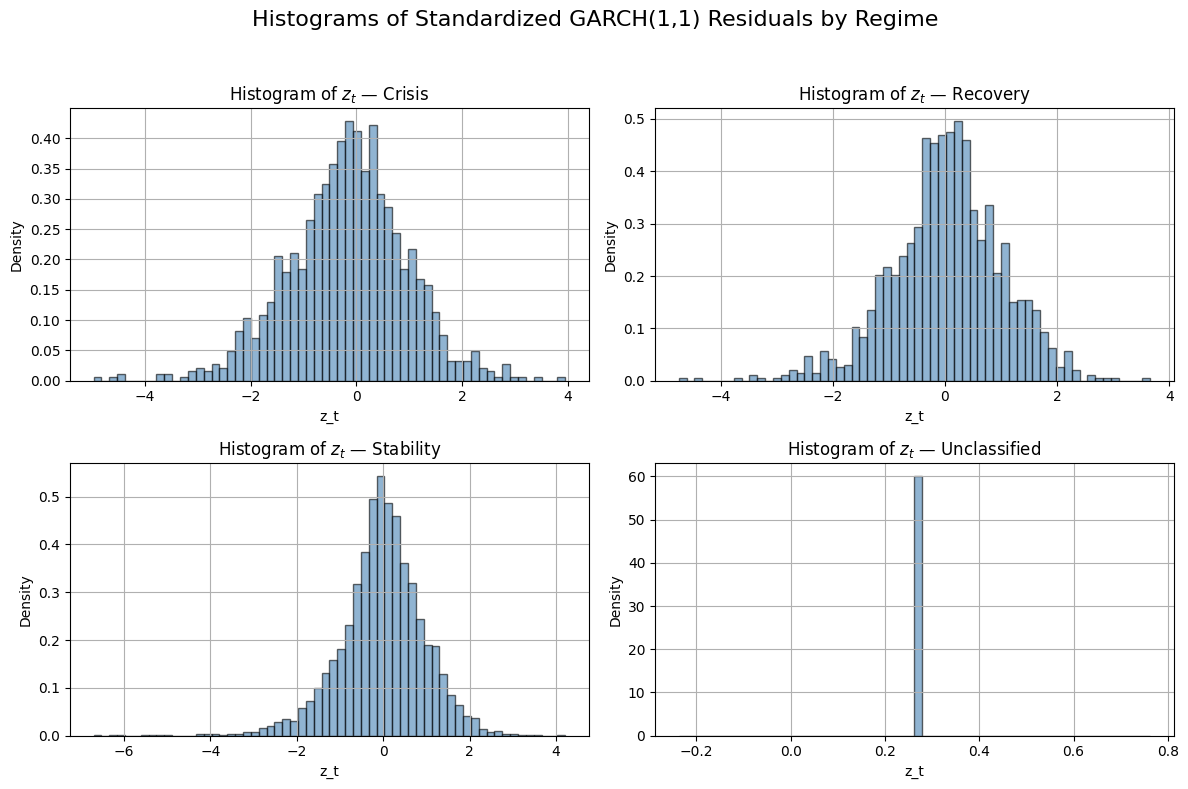

In [ ]:
df_garch, fit = fit_global_garch_and_add_volatility("SPX_with_regimes.xlsx")
residual_moments = analyze_standardized_residuals_by_regime(df_garch)

## Section: Regime-Aware GARCH(1,1) Modeling and Residual Analysis

This section focuses on fitting a **GARCH(1,1) model with regime-specific parameters**, and analyzing whether this additional structure leads to meaningful improvements over a single global GARCH model.

---

### 1. **Motivation**

Our goal is to test whether the statistical properties of volatility truly differ between regimes — and whether this justifies moving toward **regime-switching volatility models** like MS-ARCH-X. Specifically, we ask:
- Does fitting separate GARCH parameters by regime capture structural volatility differences?
- Do standardized residuals behave differently across regimes?
- Are there asymmetric volatility effects within regimes?

---

### 2. **Methodology: Regime-Specific GARCH(1,1) Estimation**

We implemented a full **custom regime-aware GARCH(1,1)** model:
- Parameters \( \omega_k, \alpha_k, \beta_k \) are estimated separately for each regime \( k \in \{\text{Stability, Crisis, Recovery}\} \)
- The likelihood is optimized under constraints: \( \omega > 0 \), \( \alpha > 0 \), \( \beta > 0 \), and \( \alpha + \beta < 1 \)
- Optimization was done using `scipy.optimize.minimize` under `SLSQP` with analytical constraints

After fitting, we computed regime-specific conditional variances \( \sigma_t^2 \), and standardized returns:

\[
z_t = \frac{r_t - \mu}{\sigma_t}
\]

---

### 3. **Residual Distribution Analysis**

We analyzed standardized residuals `z_t` **within each regime**:
- Plotted histograms
- Computed statistical moments: **mean**, **standard deviation**, **skewness**, and **kurtosis**

This was done using the function:

```python
analyze_regime_garch_residuals(filepath)
```

---

### 4. **Findings**

Despite the model respecting the regime structure, **residual distributions were not dramatically different** from those observed in the global GARCH fit. Some regimes showed slightly more skew or excess kurtosis, but:

> There was no strong statistical or visual justification for three distinct volatility regimes **based solely on residual behavior**.

This means that while the regime-aware model is theoretically more flexible, the observed benefit from this additional complexity — based on standardized residuals — is limited.

---

### 5. **Additional Diagnostic: Volatility Asymmetry**

To probe further, we investigated whether **volatility clustering differs** between **positive and negative returns** — a known feature in financial markets.

#### Methods:
- Computed 40-day rolling standard deviations for positive and negative returns
- Plotted these over time with regime shading
- Computed, for each regime:
  - Std dev of positive returns
  - Std dev of negative returns
  - Their ratio (asymmetry indicator)

#### Result:
```python
pd.DataFrame(asymmetry_results, columns=["Regime", "Std_Pos", "Std_Neg", "Asymmetry_Ratio"])
```

---

### ⚠️ Conclusion of This Section

While a regime-aware GARCH model does bring additional structure, **the empirical evidence in our tests does not clearly justify three volatility regimes**:
- Residual distributions were broadly similar across regimes
- Volatility asymmetry appeared inconsistent and inconclusive

---



In [ ]:
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

valid_regimes = ['Stability', 'Crisis', 'Recovery']
mask = df["Regime"].isin(valid_regimes)

fit_result = fit_regime_garch(df.loc[mask, "Return"], df.loc[mask, "Regime"])


You’re fitting a regime-aware GARCH(1,1) model with separate parameters per regime, but crucially:

The volatility process is computed over the entire time series.

At each time t, the GARCH equation uses the parameters corresponding to the regime at that time.

This is not a Markov-switching GARCH, but rather a deterministic regime-partitioned GARCH — which is well-suited to your context (non-overlapping, known regimes).

The volatility series is still continuous, but regime switching happens at known, discrete times.

You don’t re-fit a GARCH model separately to each regime, but instead use one global log-likelihood with regime-aware GARCH updates.

This approach only works because the regimes are known a priori — if they were latent (unknown), you'd need a Hidden Markov Model or MS-GARCH.

=== Standardized Residual Moments by Regime ===

Regime: Stability
  Mean     : 0.0563
  Std Dev  : 0.9979
  Skewness : -0.5271
  Kurtosis : 5.2463

Regime: Crisis
  Mean     : -0.1036
  Std Dev  : 1.0000
  Skewness : -0.1714
  Kurtosis : 3.7600

Regime: Recovery
  Mean     : 0.1015
  Std Dev  : 0.9926
  Skewness : -0.3084
  Kurtosis : 3.9737



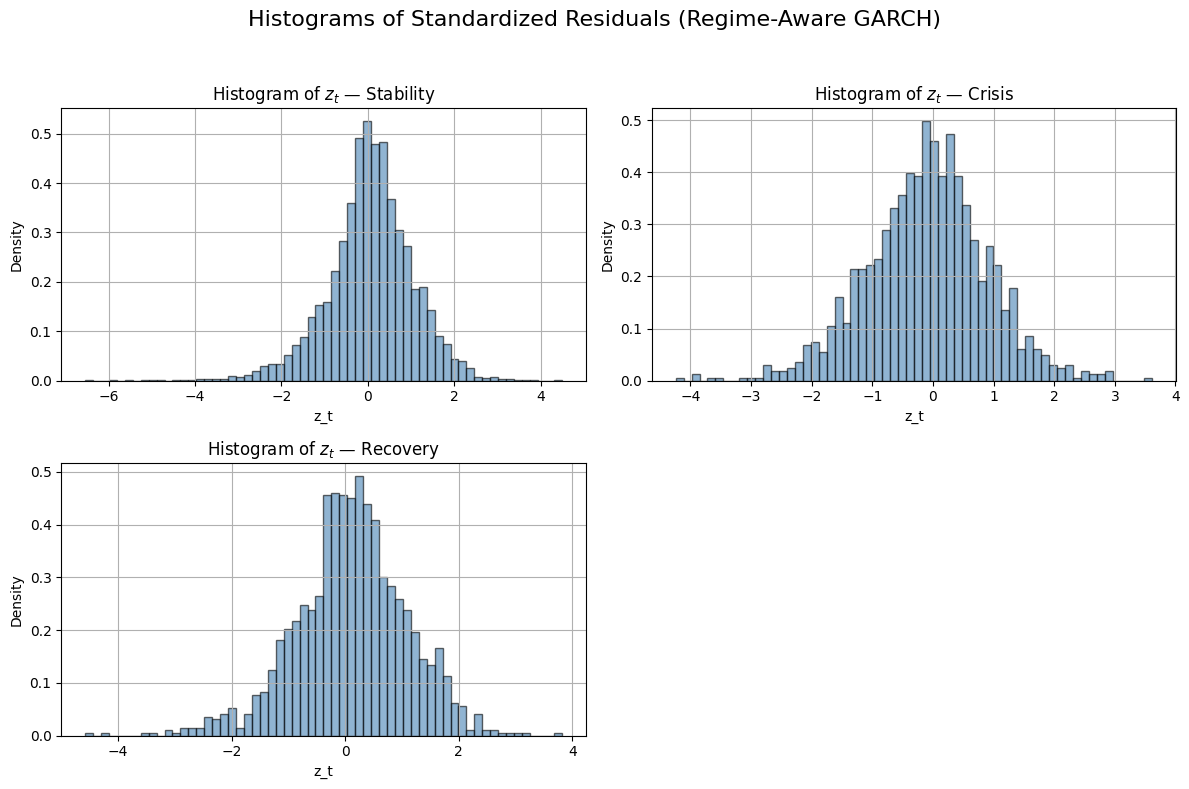

In [ ]:
result = analyze_regime_garch_residuals("SPX_with_regimes.xlsx")

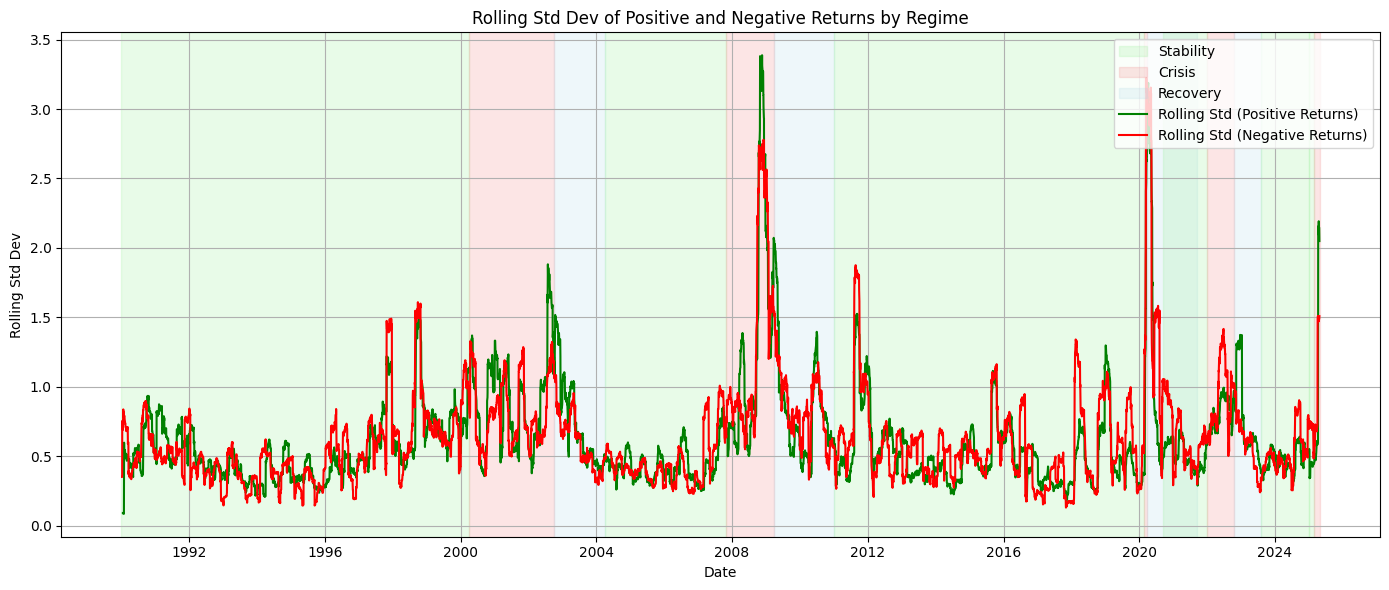

In [ ]:
import matplotlib.pyplot as plt

#Volatility asymmetry doesn't appear randomly, clusters within regimes, justifying regime-switching volatility model --> Doesn't work :(

# Window size in days
window = 40

# Positive and negative returns masks
returns = df["Return"]
#rolling_std_pos = returns.where(returns > 0).rolling(window).std()
#rolling_std_neg = returns.where(returns < 0).rolling(window).std()

rolling_std_pos = returns.where(returns > 0).rolling(window=window, min_periods=5).std()
rolling_std_neg = returns.where(returns < 0).rolling(window=window, min_periods=5).std()


# Prepare plot
fig, ax = plt.subplots(figsize=(14, 6))

# Shade regime periods
regime_colors = {"Stability": "lightgreen", "Crisis": "lightcoral", "Recovery": "lightblue"}
for start, end, regime in regime_periods:
    ax.axvspan(pd.to_datetime(start), pd.to_datetime(end), color=regime_colors[regime], alpha=0.2, label=regime)

# Plot the rolling std devs
ax.plot(df["Date"], rolling_std_pos, label="Rolling Std (Positive Returns)", color="green")
ax.plot(df["Date"], rolling_std_neg, label="Rolling Std (Negative Returns)", color="red")

# Fix legend to avoid duplicates
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), loc="upper right")

ax.set_title("Rolling Std Dev of Positive and Negative Returns by Regime")
ax.set_ylabel("Rolling Std Dev")
ax.set_xlabel("Date")
ax.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
asymmetry_results = []

for regime in sorted(df["Regime"].unique()):
    subset = df[df["Regime"] == regime]["Return"]
    std_pos = subset[subset > 0].std()
    std_neg = subset[subset < 0].std()
    ratio = std_neg / std_pos if std_pos != 0 else np.nan
    asymmetry_results.append((regime, std_pos, std_neg, ratio))

pd.DataFrame(asymmetry_results, columns=["Regime", "Std_Pos", "Std_Neg", "Asymmetry_Ratio"])



,Regime,Std_Pos,Std_Neg,Asymmetry_Ratio
0,Crisis,1.442630,1.430131,0.991337
1,Recovery,0.838949,0.795563,0.948285
2,Stability,0.585561,0.659772,1.126735
3,Unclassified,NaN,NaN,NaN


## 📈 Sector-Based Correlation and Regime-Aware Volatility Analysis

This section aimed to explore the co-movement between the S&P 500 and its underlying sector indices using regime-aware volatility modeling. Our objective was to identify structural correlation differences across regimes (Stability, Crisis, Recovery) and search for any stylized facts that could justify a 3-regime volatility model.

---

### 🗂️ Dataset and Preprocessing

We worked with two main datasets:
1. **SPX Sub-Indices** from `"spx_sectors.xlsx"` (11 columns: SPX and 10 sectors).
2. **Constituent Stocks** from `yfinance`, exported as `"spx_stocks_clean.xlsx"` — used for potential future extensions, but not analyzed here.

Each date was assigned a regime label using the predefined `regime_periods`. This allowed all subsequent volatility and correlation analysis to be segmented regime by regime.

---

### ⚙️ ARCH(1) Analysis: SPX vs CAC

We fitted an **ARCH(1)** model on both SPX and CAC returns across regimes to compare volatility dynamics across geographies.

For each regime, we extracted:
- `mu`: Mean return
- `alpha0`: Baseline variance
- `alpha1`: Clustering term

These parameters were stored and tabulated for comparison. While ARCH is a univariate model and not well-suited for analyzing inter-market volatility transmission, it provided useful diagnostic contrast between the two indices.

We also computed the **correlation between the conditional volatilities** of SPX and CAC from ARCH(1) models across regimes. While this correlation isn’t theoretically rigorous (due to model independence), it offered some exploratory value.

---

### 🔄 Regime-Aware GARCH Standardization

We introduced regime-specific GARCH(1,1) fitting using:

- `fit_regime_garch(...)`
- `compute_sigma2_regime(...)`

Each return series was standardized using its own per-regime conditional volatility:
\[
z_{t}^{(i)} = \frac{r_t^{(i)}}{\sqrt{\sigma_t^{2(i)}}}
\]

This enabled fairer correlation comparisons across regimes by correcting for regime-specific heteroskedasticity.

---

### 🔍 Correlation Matrices: Raw vs Standardized

For each regime (`Stability`, `Crisis`, `Recovery`), we computed:

- **Raw correlation matrix** using unstandardized log returns
- **Standardized correlation matrix** using regime-GARCH-normalized returns

Both were plotted using seaborn heatmaps. These allowed us to identify:
- Higher and tighter sector co-movement during crises
- More dispersion and sectoral decoupling in stability and recovery

The matrices revealed visually that regime structure meaningfully impacts correlation.

---

### 🧮 Regime Correlation Comparison: Matrix Deltas

We studied correlation matrix differences using:

```python
corr_study      = raw_corr['Crisis'] - raw_corr['Stability']
corr_std_study  = std_corr['Crisis'] - std_corr['Stability']
dev_study       = raw_corr['Crisis'] - std_corr['Crisis']
```

These were visualized using heatmaps and helped quantify:

- How much raw correlation structure changes from Stability to Crisis  
- Whether standardization reduces regime contrast  
- How much of the observed co-movement in Crisis is driven by volatility  

We observed that:

- `corr_study` showed elevated correlation in Crisis vs Stability  
- `corr_std_study` had smaller values — showing GARCH normalization removes some regime-specific inflation  
- `dev_study` revealed how raw crisis correlations were inflated relative to true co-movement  

---

### 📊 Rolling Correlation with Regime Coloring

We implemented a function using Plotly:

```python
plot_rolling_correlation_plotly_regime_aware(df, target="SPX", index="S5MATR", 
                                             rolling_window=40, log_returns=True, standardize=True)
```

This plotted the rolling correlation between SPX and a chosen sector, color-coded by regime. It broke correlation lines at regime transitions using `Block ID`.

✅ When plotting **SPX vs S5MATR (Materials)**, we observed:

- Sudden drops in correlation **below 0.4**
- These **often preceded crises**, though not reliably or immediately
- While not predictive, the plot helped **visually interpret transitions**

---

### 🧠 Key Takeaways

- **Crisis periods** exhibit stronger and more uniform correlation across sectors  
- **Volatility adjustment** via regime-aware GARCH improves correlation interpretability  
- **Correlation matrices** change meaningfully between regimes — particularly before/after crises  
- **Rolling correlations** offer intuitive visual cues of structural breaks, but are not predictive  
- Although exploratory, the combined evidence **justifies a 3-regime model** more clearly than univariate volatility fitting  

This section strongly supports the **structural regime hypothesis**, and sets the foundation for future multivariate or predictive modeling using correlation structure.


In [ ]:
#Load data and set regimes
import pandas as pd
import numpy as np
from arch import arch_model

# Load Excel and rename columns
df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index', 'VIX Index', 'CAC Index']]
df.columns = ['Date', 'SPX Index', 'VIX Index', 'CAC Index']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')


# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
    return "Unclassified"

df['Regime'] = df['Date'].apply(assign_regime)


In [ ]:
df['SPX Return'] = np.log(df['SPX Index']).diff() * 100
df['CAC Return'] = np.log(df['CAC Index']).diff() * 100
df = df.dropna(subset=['SPX Return', 'CAC Return'])

# Prepare to collect results
spx_results = []
cac_results = []

for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    spx_ret = df.loc[mask, 'SPX Return'].dropna()
    cac_ret = df.loc[mask, 'CAC Return'].dropna()

    if len(spx_ret) < 100 or len(cac_ret) < 100:
        print(f"Skipping {label} ({start}–{end}) — insufficient data.")
        continue

    # ARCH(1) for SPX
    spx_fit = arch_model(spx_ret, vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False).fit(disp='off')
    spx_vol = spx_fit.conditional_volatility

    spx_params = spx_fit.params
    spx_results.append({
        'Regime': label,
        'Start': start,
        'End': end,
        'mu': spx_params.get('mu'),
        'alpha0': spx_params.get('omega'),
        'alpha1': spx_params.get('alpha[1]')
    })

    # ARCH(1) for CAC
    cac_fit = arch_model(cac_ret, vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False).fit(disp='off')
    cac_vol = cac_fit.conditional_volatility
    
    cac_params = cac_fit.params
    cac_results.append({
        'Regime': label,
        'Start': start,
        'End': end,
        'mu': cac_params.get('mu'),
        'alpha0': cac_params.get('omega'),
        'alpha1': cac_params.get('alpha[1]')
    })


# Build DataFrame
spx_df = pd.DataFrame(spx_results).add_suffix('_SPX')
cac_df = pd.DataFrame(cac_results).add_suffix('_CAC')

# Merge on Regime + Period
comparison_df = spx_df.merge(
    cac_df,
    left_on=["Regime_SPX", "Start_SPX", "End_SPX"],
    right_on=["Regime_CAC", "Start_CAC", "End_CAC"]
)

# Clean and select columns
comparison_df['Regime'] = comparison_df['Regime_SPX']
comparison_df = comparison_df[[
    'Regime', 'mu_SPX', 'alpha0_SPX', 'alpha1_SPX',
    'mu_CAC', 'alpha0_CAC', 'alpha1_CAC'
]].round(4)

# Display comparison table
print("\n=== ARCH(1) Parameter Comparison: SPX vs CAC by Regime ===\n")
print(comparison_df.to_string(index=False))

Skipping Crisis (2020-02-18–2020-03-24) — insufficient data.
Skipping Stability (2025-01-01–2025-02-20) — insufficient data.
Skipping Crisis (2025-02-20–2025-04-30) — insufficient data.

=== ARCH(1) Parameter Comparison: SPX vs CAC by Regime ===

   Regime  mu_SPX  alpha0_SPX  alpha1_SPX  mu_CAC  alpha0_CAC  alpha1_CAC
Stability  0.0586      0.6823      0.1944  0.0598      1.2950      0.1509
   Crisis -0.0759      1.7177      0.1716 -0.1249      2.8404      0.1072
 Recovery  0.0715      1.0546      0.2022  0.0437      1.9468      0.2970
Stability  0.0356      0.4990      0.0402  0.0569      0.6891      0.1310
   Crisis -0.1550      4.7385      0.2275 -0.1897      4.1806      0.3100
 Recovery  0.1037      1.4599      0.0000  0.0843      1.8415      0.1371
Stability  0.0546      0.6109      0.2538  0.0312      1.0497      0.2916
 Recovery  0.2044      0.8333      0.6759  0.1088      1.6797      0.0514
Stability  0.0917      0.6093      0.2424  0.1190      0.9442      0.1456
   Crisis -0.

In [ ]:
from arch import arch_model
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

regime_vol_corrs = []

# === Fit ARCH(1) models and compute volatility correlation per period ===
for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.to_datetime(start)) & (df['Date'] <= pd.to_datetime(end))
    subset = df.loc[mask].copy()
    
    if len(subset) < 100:
        print(f"Skipping {label} {start}–{end} — too short.")
        continue

    # Fit SPX ARCH(1)
    spx_fit = arch_model(subset['SPX Return'], vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    spx_vol = spx_fit.conditional_volatility

    # Fit CAC ARCH(1)
    cac_fit = arch_model(subset['CAC Return'], vol='ARCH', p=1, mean='Constant', dist='normal').fit(disp='off')
    cac_vol = cac_fit.conditional_volatility

    # Ensure same length and index alignment
    if len(spx_vol) != len(cac_vol):
        print(f"Length mismatch in {label} {start}–{end}, skipping.")
        continue

    # Compute correlation
    corr, _ = pearsonr(spx_vol, cac_vol)

    regime_vol_corrs.append({
        "Regime": label,
        "Start": start,
        "End": end,
        "Vol_Corr": round(corr, 4)
    })

# === Convert to DataFrame and display ===
vol_corr_df = pd.DataFrame(regime_vol_corrs)
print("\n=== Volatility Correlation Between SPX and CAC (ARCH(1)) ===\n")
print(vol_corr_df.to_string(index=False))



/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_4415/1603557351.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(spx_vol, cac_vol)
/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_4415/1603557351.py:31: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(spx_vol, cac_vol)


Skipping Crisis 2020-02-18–2020-03-24 — too short.
Skipping Stability 2025-01-01–2025-02-20 — too short.
Skipping Crisis 2025-02-20–2025-04-30 — too short.

=== Volatility Correlation Between SPX and CAC (ARCH(1)) ===

   Regime      Start        End  Vol_Corr
Stability 1990-01-01 2000-03-31    0.2981
   Crisis 2000-04-01 2002-09-30    0.4303
 Recovery 2002-10-01 2004-03-31    0.5977
Stability 2004-04-01 2007-10-31    0.3909
   Crisis 2007-11-01 2009-03-31    0.5350
 Recovery 2009-04-01 2010-12-31       NaN
Stability 2011-01-01 2020-02-17    0.5272
 Recovery 2020-03-25 2021-09-15    0.4795
Stability 2020-09-16 2021-12-31    0.3493
   Crisis 2022-01-01 2022-10-12       NaN
 Recovery 2022-10-13 2023-07-31    0.2104
Stability 2023-08-01 2024-12-31    0.1601


In [ ]:
#IMPORTING STOCKS OF SPX

import yfinance as yf
#Importing data and trying to format it as data

# === Step 1: Download adjusted close prices ===
tickers = ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'JPM']
data = yf.download(tickers, start="1990-01-01", end="2025-04-30", auto_adjust=True)

# === Step 2: Flatten column index if needed ===
if isinstance(data.columns, pd.MultiIndex):
    data = data.droplevel(0, axis=1)

# === Step 3: Rename columns
data.columns = [f"{ticker}" for ticker in data.columns]

# === Step 4: Reset index (Date column still datetime)
data = data.reset_index()

# === ✅ Step 5: Sort DESCENDING based on datetime BEFORE converting to string
data = data.sort_values("Date", ascending=False)

# === Step 6: Convert to "DD/MM/YYYY" format AFTER sorting
data["Date"] = data["Date"].dt.strftime('%d/%m/%Y')

# === Step 7: Add "Equity" metadata row
meta_row = ['Equity'] * data.shape[1]
meta_df = pd.DataFrame([meta_row], columns=data.columns)

# === Step 8: Combine and save
final_df = pd.concat([meta_df, data], ignore_index=True)
final_df.to_excel(DATA / "spx_stocks_clean.xlsx", index=False)

[*********************100%***********************]  5 of 5 completed


| Code       | Sector Name            | Description                                                                                                    |
| ---------- | ---------------------- | -------------------------------------------------------------------------------------------------------------- |
| **S5CONS** | Consumer Staples       | Companies providing essential products (food, beverages, household goods) — e.g., Procter & Gamble, Coca-Cola. |
| **S5ENRS** | Energy                 | Oil, gas, and consumable fuels — e.g., ExxonMobil, Chevron.                                                    |
| **S5HLTH** | Health Care            | Pharmaceuticals, biotechnology, and medical devices — e.g., Johnson & Johnson, Pfizer.                         |
| **S5FINL** | Financials             | Banks, insurance companies, investment services — e.g., JPMorgan, Goldman Sachs.                               |
| **S5UTIL** | Utilities              | Electric, gas, and water utilities — e.g., Duke Energy, NextEra Energy.                                        |
| **S5MATR** | Materials              | Chemical, construction, and packaging materials — e.g., DuPont, International Paper.                           |
| **S5INFT** | Information Technology | Software, hardware, and IT services — e.g., Apple, Microsoft.                                                  |
| **S5INDU** | Industrials            | Transportation, machinery, aerospace, logistics — e.g., Boeing, FedEx.                                         |
| **S5TELS** | Communication Services | Telecom, media, and entertainment — e.g., Google, Meta, Verizon.                                               |
| **S5COND** | Consumer Discretionary | Retail, autos, luxury goods, travel — e.g., Amazon, Nike, Starbucks.                                           |


In [139]:
# Load Excel and rename columns
df = pd.read_excel(DATA / "spx_sectors.xlsx", skiprows=0)
df = df[['Dates', 'SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL','S5MATR','S5INFT','S5INDU','S5TELS','S5COND']]
df.columns = ['Date', 'SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL','S5MATR','S5INFT','S5INDU','S5TELS','S5COND']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')


# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-07', 'Crisis'),
    ('2025-04-08', '2025-06-18', 'Recovery'),
]

def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
    return 'Undef'

df['Regime'] = df['Date'].apply(assign_regime)

In [34]:

"""
    Computes correlation between two return series (raw and standardized) by regime using regime-aware GARCH volatility.

    Parameters:
    - df: DataFrame with return columns and regime label
    - col1, col2: str, names of return columns (e.g., "SPX Return", "CAC Return")
    - regime_col: name of the regime column (default "Regime")
    - K: number of regimes (default 3)

    Returns:
    - DataFrame with raw and standardized correlations by regime
"""

df['SPX Return'] = np.log(df['SPX']).diff() * 100
df['S5INDU Return'] = np.log(df['S5INDU']).diff() * 100
df = df.dropna()

result_df = regime_correlation_analysis(df, "SPX Return",'S5INDU Return', regime_col="Regime")
pd.DataFrame(result_df)



/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_4415/3976767899.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['SPX Return'] = np.log(df['SPX']).diff() * 100
/var/folders/2g/43vdtj911db4ry8x4s1gy_jr0000gq/T/ipykernel_4415/3976767899.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['S5INDU Return'] = np.log(df['S5INDU']).diff() * 100


,Regime,SPX Return vs S5INDU Return Raw Corr,SPX Return vs S5INDU Return Std Corr
0,Crisis,0.924022,0.894508
1,Recovery,0.899020,0.880193
2,Stability,0.905550,0.888827


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# === SETUP ===
sectors = ['SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL',
           'S5MATR','S5INFT','S5INDU','S5TELS','S5COND']

# 1. Compute log returns
for col in sectors:
    df[f"{col}_ret"] = np.log(df[col]).diff() * 100

df = df.dropna().copy()

# 2. Compute regime-specific GARCH volatilities for each sector
# We'll store them in new columns: f"{col}_sigma"

from functions_jules import fit_regime_garch, compute_sigma2_regime

print("⚙️ Fitting regime-aware GARCH volatilities...")

for col in sectors:
    y = df[f"{col}_ret"].values
    regimes = df["Regime"].values

    # Fit regime-aware GARCH(1,1)
    fit_result = fit_regime_garch(y, regimes, expected_labels=["Stability", "Crisis", "Recovery"])
    params = fit_result["params"]
    mapping = fit_result["mapping"]
    reverse_mapping = fit_result["reverse_mapping"]

    # Get integer regime sequence and compute conditional variance
    reg_num = np.array([mapping[r] for r in regimes])
    sigma2 = compute_sigma2_regime(y, reg_num, params, reverse_mapping)

    df[f"{col}_sigma"] = np.sqrt(sigma2)

# 3. Standardize returns using regime-aware GARCH volatility
for col in sectors:
    df[f"{col}_z"] = df[f"{col}_ret"] / df[f"{col}_sigma"]

# === CORRELATION MATRICES BY REGIME ===
regimes = ['Crisis', 'Recovery', 'Stability']
raw_corr = {}
std_corr = {}

for regime in regimes:
    print(f"\n==== {regime.upper()} ====\n")
    sub = df[df["Regime"] == regime].copy()

    # Raw return correlation
    raw = sub[[f"{col}_ret" for col in sectors]].corr()
    raw.index = raw.columns = sectors
    raw_corr[regime] = raw

    # Standardized return correlation
    std = sub[[f"{col}_z" for col in sectors]].corr()
    std.index = std.columns = sectors
    std_corr[regime] = std

    # Plot raw correlation matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(raw, square=True, annot=True, cmap='crest', fmt=".2f")
    plt.title(f"{regime} — Raw Correlation")
    plt.tight_layout()
    plt.show()

    # Plot standardized correlation matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(std, square=True, annot=True, cmap='crest', fmt=".2f")
    plt.title(f"{regime} — Regime-Aware Standardized Correlation")
    plt.tight_layout()
    plt.show()


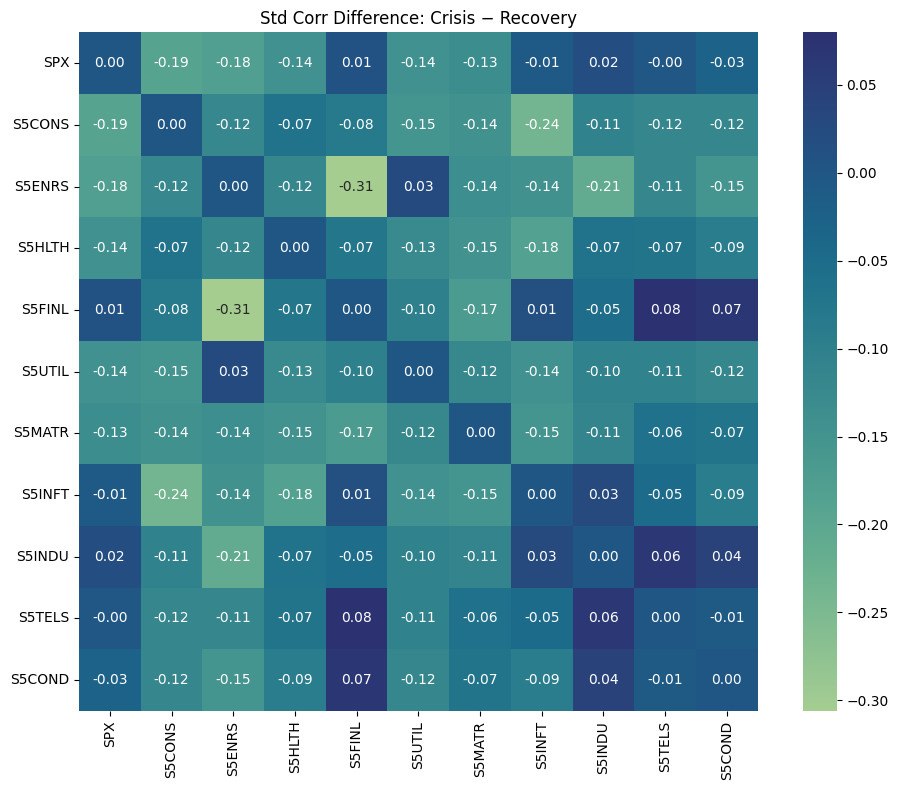

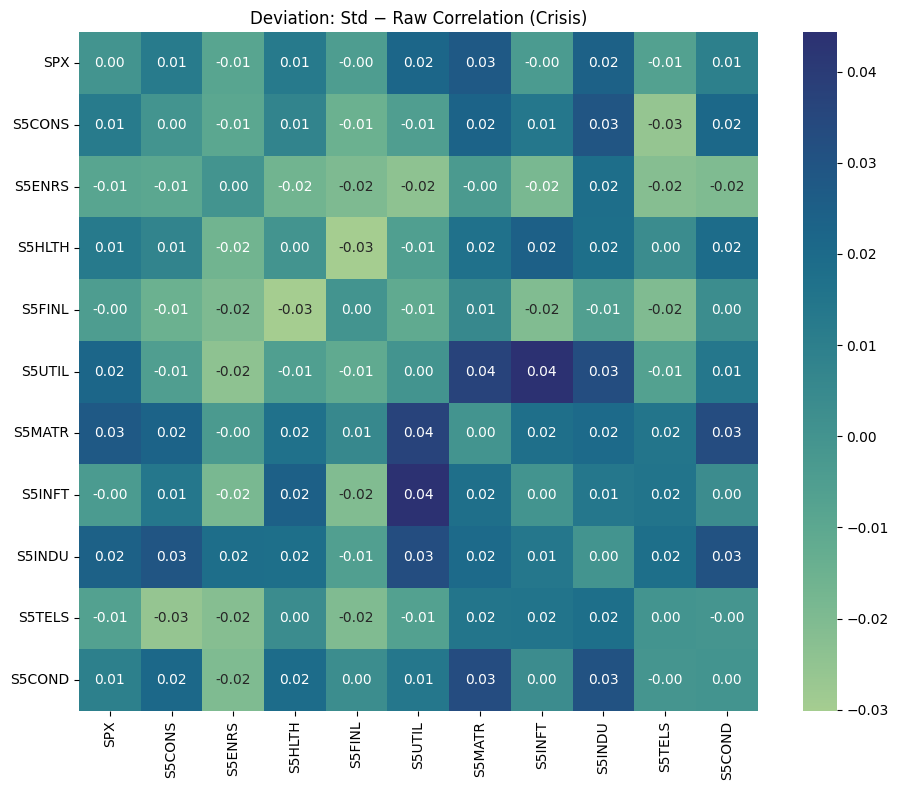

In [150]:
regime1 = 'Crisis'
regime2 = 'Recovery'

corr_study = raw_corr[regime1] - raw_corr[regime2]
corr_std_study = std_corr[regime1] - std_corr[regime2]
dev_study = -std_corr[regime2] + raw_corr[regime2]

# Plotting
for title, matrix in [
    #(f"Raw Corr Difference: {regime1} − {regime2}", corr_study),
    (f"Std Corr Difference: {regime1} − {regime2}", corr_std_study),
    (f"Deviation: Std − Raw Correlation ({regime1})", dev_study)
]:
    plt.figure(figsize=(10, 8))
    sns.heatmap(matrix, square=True, annot=True, cmap='crest', fmt=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()


In [41]:
#Presentation of the tables (Chatgpt)

import pandas as pd
from IPython.display import display, HTML

# Drop rows where all correlation values are missing
clean_df = final_result_df.dropna(subset=[
    col for col in final_result_df.columns if "Corr" in col
], how="all").copy()

# Collect sector tables as HTML strings
sector_tables = []
for sector in sorted(clean_df["Sector"].unique()):
    sub = clean_df[clean_df["Sector"] == sector].copy()
    corr_cols = [c for c in sub.columns if "Corr" in c and sub[c].notna().any()]
    if len(corr_cols) != 2:
        continue
    mini = sub[["Regime"] + corr_cols].dropna(how="all").reset_index(drop=True)
    mini.columns = ["Regime", "Raw Corr", "Std Corr"]
    mini_html = mini.style.set_table_attributes('style="margin: 10px;"')\
                          .set_caption(f"Sector: {sector}")\
                          .format(precision=4)\
                          .to_html()
    sector_tables.append(mini_html)

# Group into rows of 5 tables
rows_html = ""
for i in range(0, len(sector_tables), 5):
    row = sector_tables[i:i+5]
    row_html = '<div style="display:flex; flex-wrap:nowrap;">' + ''.join(row) + '</div>'
    rows_html += row_html

# Display all
display(HTML(rows_html))


,Regime,Raw Corr,Std Corr
0,Crisis,0.9035,0.8751
1,Recovery,0.9063,0.8921
2,Stability,0.8977,0.8856
,Regime,Raw Corr,Std Corr
0,Crisis,0.7102,0.5750
1,Recovery,0.7625,0.7436
2,Stability,0.7556,0.7435
,Regime,Raw Corr,Std Corr
0,Crisis,0.7042,0.5271
1,Recovery,0.6650,0.6624


In [136]:
# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-07', 'Crisis'),
    ('2025-04-08', '2025-06-18', 'Recovery'),
]

In [60]:
plot_rolling_correlation_plotly_regime_aware(df, target="SPX", index="S5MATR", rolling_window=40,
                                             log_returns=True, standardize=True) 


/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning:

Values in x were outside bounds during a minimize step, clipping to bounds



**Correlation matrix not with garch aware vol but garch fit to each period** **--> doesn't change a lot**

## 🔄 Correlation Analysis Using Per-Period GARCH Standardization

In our earlier analysis, we standardized sector returns using a regime-aware GARCH model applied globally across time. Here, we refine this approach by fitting **a separate GARCH(1,1) model within each regime period**, for each index independently.

---

### 🧮 Fitting GARCH Locally by Regime Segment

For each sector and regime window (e.g. Crisis 2007–2009), we:

- Computed log returns
- Fitted a GARCH(1,1) model on the local segment
- Reconstructed the conditional volatility (σ)
- Used it to standardize returns:  
  $$
  z_t = \frac{r_t}{\sigma_t^{\text{(GARCH)}}}
  $$

This avoids look-ahead bias and ensures that standardization is **regime-local** and economically realistic.

---

### 🧭 Correlation Matrices by Regime

We then computed correlation matrices using:

- **Raw returns** (unadjusted)
- **GARCH-standardized returns** (based on local fits)

Each was plotted by regime (Crisis, Recovery, Stability), allowing us to assess structural co-movement across sectors both in level and standardized terms.

📌 This more localized method improves the robustness of cross-sectional correlation analysis within distinct economic regimes.


In [ ]:
# Define your sectors and regimes
sectors = ['SPX','S5CONS','S5ENRS','S5HLTH','S5FINL','S5UTIL',
           'S5MATR','S5INFT','S5INDU','S5TELS','S5COND']
regime_labels = ['Crisis', 'Recovery', 'Stability']

# Step 1: Add GARCH(1,1) per-period volatility and standardization
df = compute_per_period_garch_vols(df, sectors, regime_periods)

# Step 2: Compute and plot correlation matrices
raw_corr, std_corr = compute_correlations_by_regime(df, sectors, regime_labels)


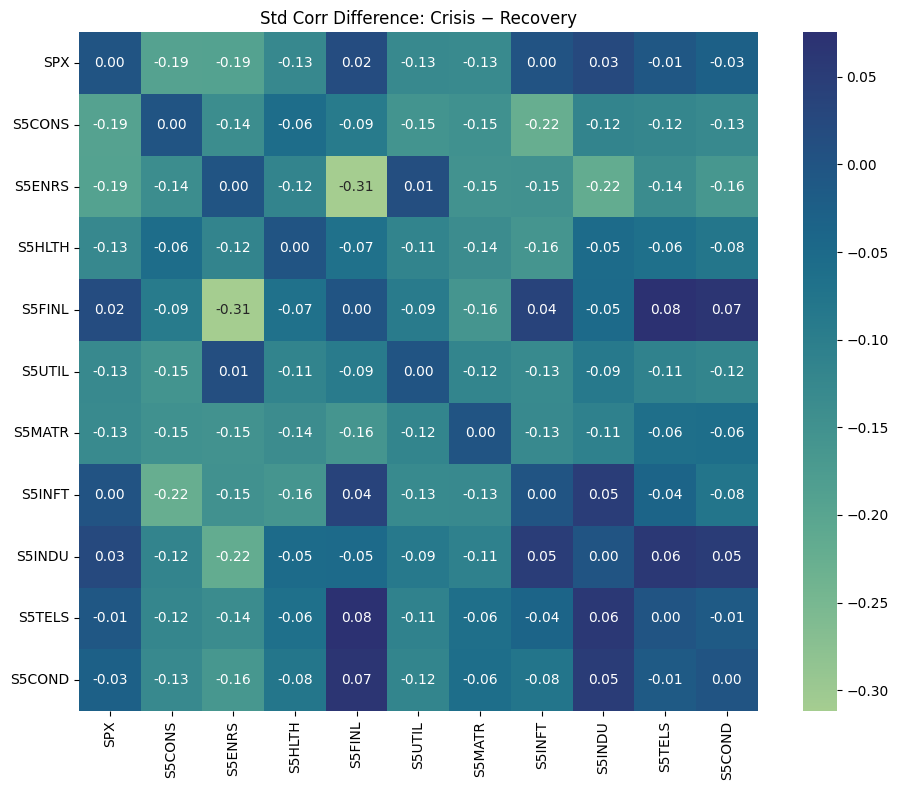

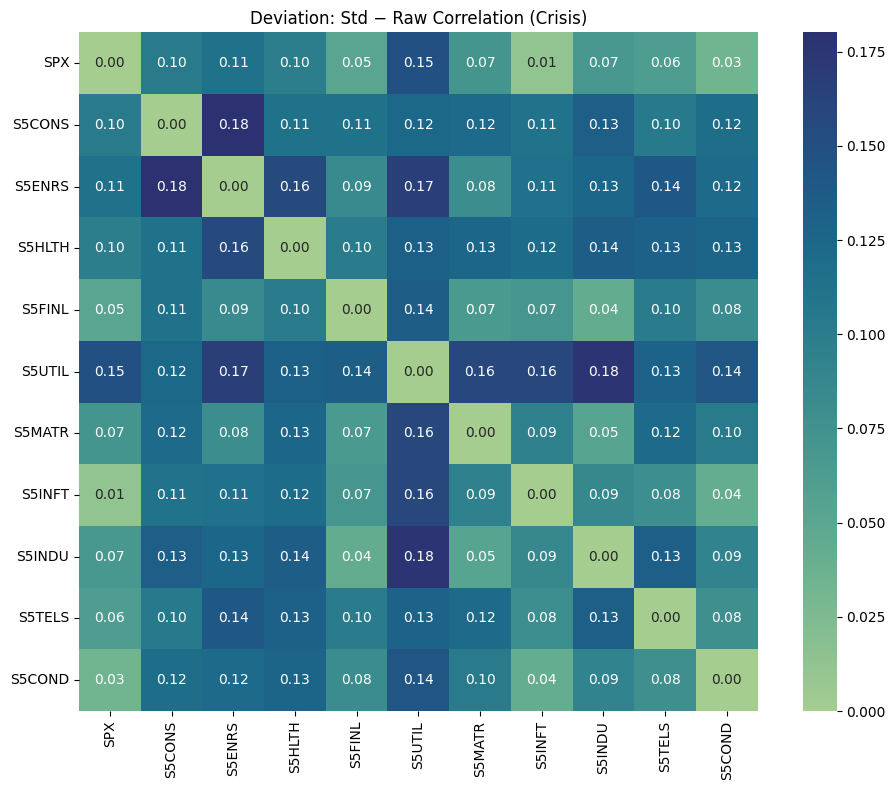

In [152]:
regime1 = 'Crisis'
regime2 = 'Recovery'

corr_study = raw_corr[regime1] - raw_corr[regime2]
corr_std_study = std_corr[regime1] - std_corr[regime2]
dev_study = -std_corr[regime2] + raw_corr[regime2]

# Plotting
for title, matrix in [
    #(f"Raw Corr Difference: {regime1} − {regime2}", corr_study),
    (f"Std Corr Difference: {regime1} − {regime2}", corr_std_study),
    (f"Deviation: Std − Raw Correlation ({regime1})", dev_study)   #--> gives the exact same thing as before
]:
    plt.figure(figsize=(10, 8))
    sns.heatmap(matrix, square=True, annot=True, cmap='crest', fmt=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()


---

## 🧭 Empirical Regime Discovery: Volatility–Return Clustering

In this final part of the section, we explored whether **regime labels could be discovered algorithmically** — without imposing predefined dates — using clustering in return–volatility space.

---

### 📊 K-Means Clustering on Return–Volatility Features

We used the same SPX data and computed two rolling features:

- **50-day average return**
- **Annualized 50-day rolling volatility**

After standardizing these features using `StandardScaler`, we applied **K-Means clustering** with `k=3`, expecting the algorithm to separate observations into groups that might correspond to:

- Stability (low vol, neutral returns)
- Crisis (high vol, often negative returns)
- Recovery (high vol, but positive returns)

```python
kmeans = KMeans(n_clusters=3)
labels = kmeans.fit_predict(X_scaled)
```

These cluster labels were visualized in return–volatility space using a colored scatterplot.

📌 **Observation**:  
Clusters were clearly distinguishable in 2D space. While no semantic label (Stability, Crisis, Recovery) was assigned to clusters, the shape and location matched expected regime archetypes.

---

### 🎯 Comparing Discovered Clusters to Assigned Regimes

To evaluate whether our manually defined regime periods aligned with the clusters:

1. We reloaded the SPX dataset.
2. Assigned regime labels using a **reduced set of periods** (only `Crisis` and `Recovery`, skipping `Stability` to avoid visual clutter).
3. Plotted the same return–volatility space, colored by manually assigned regimes.

```python
for regime in df['Regime'].unique():
    plt.scatter(df[df['Regime'] == regime]['Rolling Return'],
                df[df['Regime'] == regime]['Rolling Volatility'],
                label=regime)
```

📌 **Insight**:  
- When **excluding Stability**, we observed that the manually assigned Crisis and Recovery periods **clustered coherently**.
- These points corresponded closely to **two of the K-Means-identified regimes**, reinforcing our earlier labels.
- Stability periods, being far more frequent and dispersed, tended to be spread across all clusters — thus **less clearly identifiable from data alone**.

---

### ✅ Interpretation

This analysis served as a **sanity check** on our predefined regimes:

- Despite not using any economic or time-based segmentation, the **data-driven clusters recovered two of the three regimes** quite naturally.
- This **confirms the Crisis and Recovery structure** present in the return–volatility dynamics.
- Stability, being more diffuse and persistent, lacks a clear signature in this simple 2D space.

🧠 **Takeaway**:  
While K-Means clustering alone cannot define regimes perfectly (especially for stability), it **validates the presence of regime structure** in financial data — supporting our hypothesis that a 3-regime model (Stability–Crisis–Recovery) is both observable and meaningful.

This closes our regime discovery and validation section, bridging data-driven methods with economic intuition.


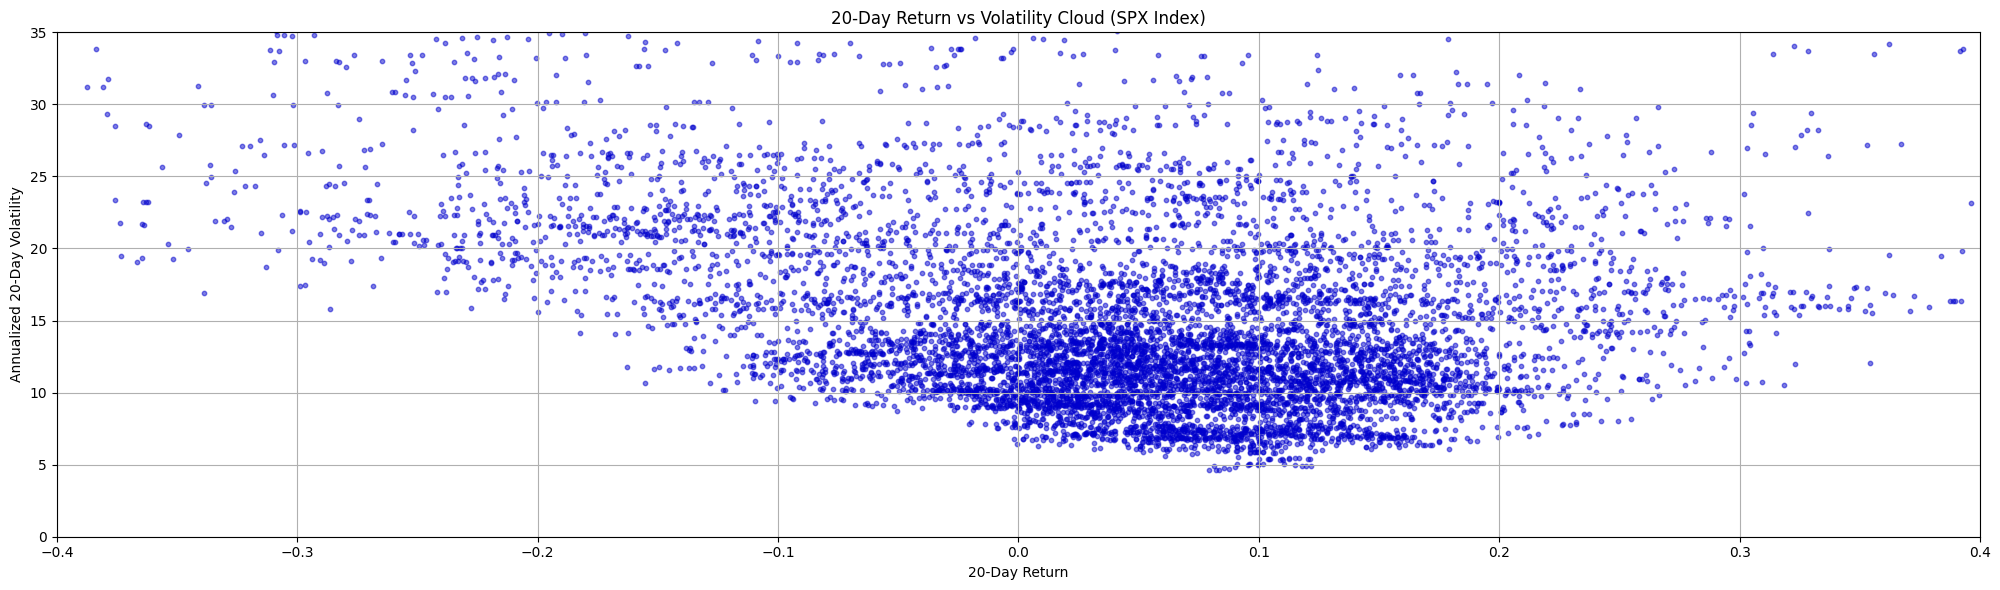

In [84]:
df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index']]
df.columns = ['Date', 'SPX']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')

#for vol
df['Daily Return'] = df['SPX'].pct_change()*100

#return of month
#df['Rolling Return'] = ((df['SPX'] / df['SPX'].shift(20)) - 1) * 100

window = 50

df['Rolling Volatility'] = df['Daily Return'].rolling(window=window).std() * np.sqrt(252)
df['Rolling Return'] = df['Daily Return'].rolling(window=window).sum() / window

df = df.dropna(subset=['Rolling Return', 'Rolling Volatility'])

plt.figure(figsize=(20, 6))
plt.scatter(df['Rolling Return'], df['Rolling Volatility'], alpha=0.5, s=10, color='mediumblue')
plt.xlabel('20-Day Return')
plt.ylabel('Annualized 20-Day Volatility')
plt.title('20-Day Return vs Volatility Cloud (SPX Index)')
plt.grid(True)
plt.tight_layout()
plt.xlim(-0.4,0.4)
plt.ylim(0,35)
plt.show()





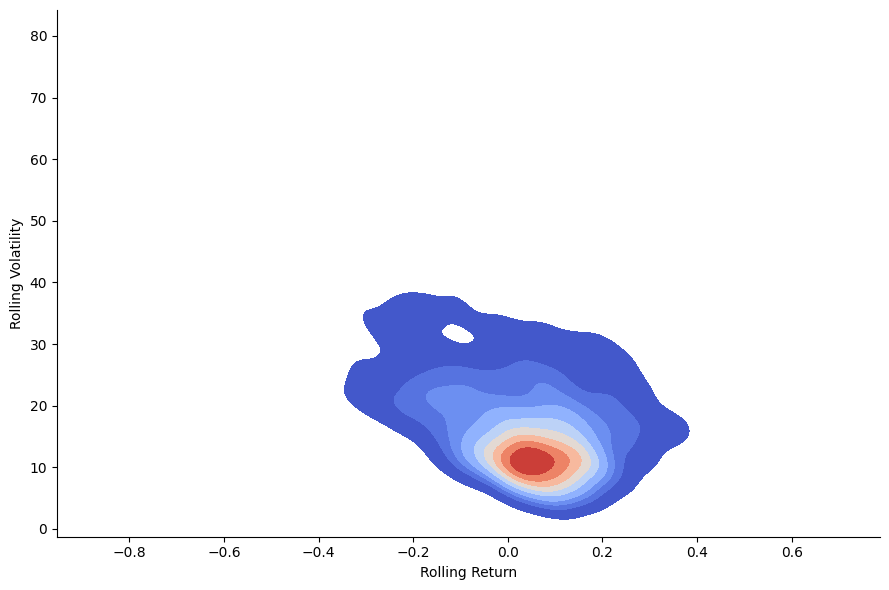

In [85]:
import seaborn as sns
import matplotlib.pyplot as plt

# 2D KDE Plot
sns.displot(
    data=df,
    x="Rolling Return",
    y="Rolling Volatility",
    kind="kde",
    fill=True,
    thresh=0.05,
    cmap="coolwarm",
    height=6,
    aspect=1.5
)

plt.show()


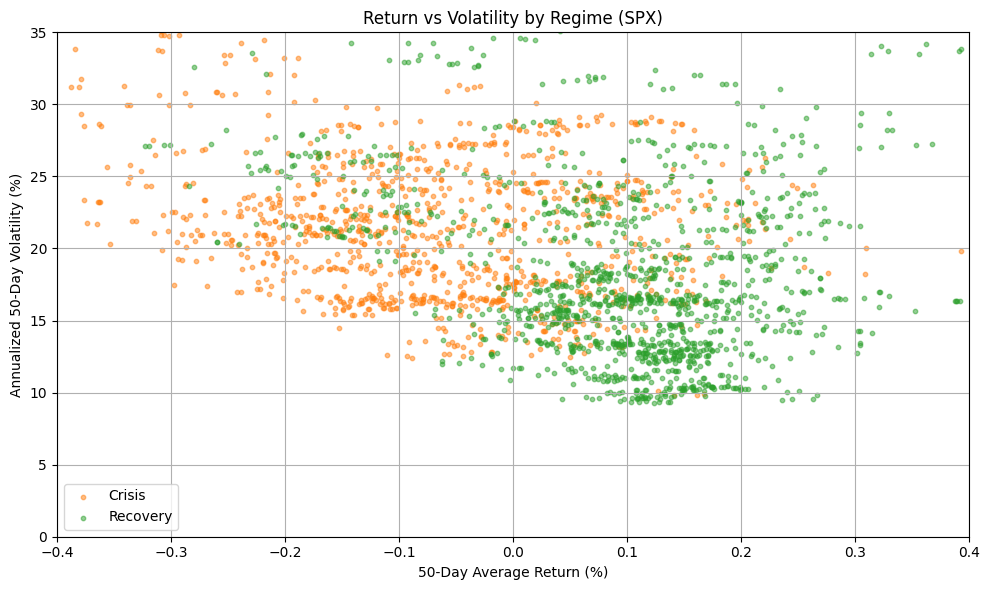

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === Step 1: Load SPX Index ===
df = pd.read_excel(DATA / "data.xlsx", skiprows=2)
df = df[['Dates', 'SPX Index']]
df.columns = ['Date', 'SPX']
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')

# === Step 2: Define Regime Periods ===
regime_periods = [
    # ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    # ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    # ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    # ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    # ('2023-08-01', '2024-12-31', 'Stability'),
    # ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# === Step 3: Assign Regimes ===
def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
        continue

df['Regime'] = df['Date'].apply(assign_regime)

# === Step 4: Compute Rolling Return and Volatility ===
window = 50
df['Daily Return'] = df['SPX'].pct_change() * 100
df['Rolling Volatility'] = df['Daily Return'].rolling(window=window).std() * np.sqrt(252)
df['Rolling Return'] = df['Daily Return'].rolling(window=window).sum() / window

df = df.dropna(subset=['Rolling Return', 'Rolling Volatility'])

# === Step 5: Plot with Regime Coloring ===
plt.figure(figsize=(10, 6))
for regime in df['Regime'].unique():
    subset = df[df['Regime'] == regime]
    plt.scatter(
        subset['Rolling Return'],
        subset['Rolling Volatility'],
        label=regime,
        alpha=0.5,
        s=10
    )

plt.xlabel('50-Day Average Return (%)')
plt.ylabel('Annualized 50-Day Volatility (%)')
plt.title('Return vs Volatility by Regime (SPX)')
plt.grid(True)
plt.xlim(-0.4, 0.4)
plt.ylim(0, 35)
plt.legend()
plt.tight_layout()
plt.show()


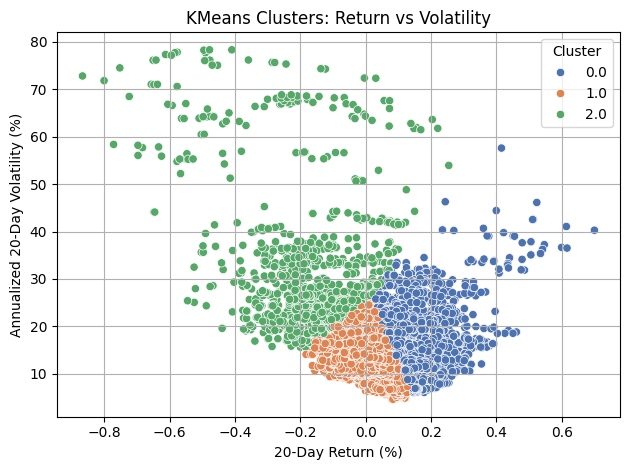

In [87]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt


X = df[['Rolling Return', 'Rolling Volatility']].dropna()

X_scaled = StandardScaler().fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_scaled)
df.loc[X.index, 'Cluster'] = labels

sns.scatterplot(
    data=df.loc[X.index],
    x='Rolling Return',
    y='Rolling Volatility',
    hue='Cluster',
    palette='deep'
)

plt.title("KMeans Clusters: Return vs Volatility")
plt.xlabel("20-Day Return (%)")
plt.ylabel("Annualized 20-Day Volatility (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


## ⚙️ GARCH(1,1) Parameter Behavior Across Regimes and Indices

In this section, we assessed whether GARCH(1,1) parameters vary meaningfully across economic regimes (Crisis, Stability, Recovery) by extending our analysis beyond the SPX index.

---

### 🧩 Expanding From SPX to Sector Indices

To overcome the limited sample size from SPX alone, we used a broader dataset — `spx_sectors.xlsx` — containing daily price data for the SPX and its 11 sector sub-indices. All indices shared the same regime segmentation.

---

### 📈 Fitting GARCH(1,1) Models by Regime

We computed percentage returns for each index and fitted a GARCH(1,1) model separately within each regime window. The resulting parameter estimates include:

- **mu**: Mean return  
- **omega**: Long-run variance  
- **alpha1**: Short-term shock sensitivity  
- **beta1**: Volatility persistence  
- **persistence**: α₁ + β₁, summarizing long-term memory

Regimes with fewer than 100 return observations were skipped.

---

### 🐝 Parameter Distributions via Swarmplots

We pooled all fitted models across indices and visualized parameter distributions using **Seaborn swarmplots**, grouped by regime. These plots revealed the spread and clustering of individual model estimates per regime.

We also printed the number of models contributing to each regime group

In [100]:
# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-07', 'Crisis'),
    ('2025-04-08', '2025-06-18', 'Recovery'),
]

✅ S5CONS — Stability — alpha0: 0.7590, alpha1: 0.2850
✅ S5CONS — Crisis — alpha0: 0.9405, alpha1: 0.2759
✅ S5CONS — Recovery — alpha0: 0.6862, alpha1: 0.1344
✅ S5CONS — Stability — alpha0: 0.3454, alpha1: 0.0517
✅ S5CONS — Crisis — alpha0: 1.4764, alpha1: 0.4921
✅ S5CONS — Recovery — alpha0: 0.5875, alpha1: 0.0160
✅ S5CONS — Stability — alpha0: 0.3973, alpha1: 0.2705
⚠️ Skipping S5CONS – Crisis (2020-02-18–2020-03-24): too few returns (26)
✅ S5CONS — Recovery — alpha0: 0.8390, alpha1: 0.0812
✅ S5CONS — Stability — alpha0: 0.5413, alpha1: 0.0000
✅ S5CONS — Crisis — alpha0: 1.1463, alpha1: 0.1327
✅ S5CONS — Recovery — alpha0: 0.5488, alpha1: 0.1211
✅ S5CONS — Stability — alpha0: 0.4283, alpha1: 0.0000
⚠️ Skipping S5CONS – Stability (2025-01-01–2025-02-20): too few returns (34)
⚠️ Skipping S5CONS – Crisis (2025-02-20–2025-04-07): too few returns (33)
⚠️ Skipping S5CONS – Recovery (2025-04-08–2025-06-18): too few returns (50)
✅ S5ENRS — Stability — alpha0: 0.9153, alpha1: 0.3080
✅ S5ENRS —

mu              alpha0              alpha1          
               mean       std      mean       std      mean       std
Regime                                                               
Crisis    -0.106719  0.123850  3.855107  3.196236  0.171725  0.163386
Recovery   0.118296  0.059418  1.624968  1.037550  0.193748  0.175031
Stability  0.059381  0.036782  0.977911  0.653413  0.141260  0.099543

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

9.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.



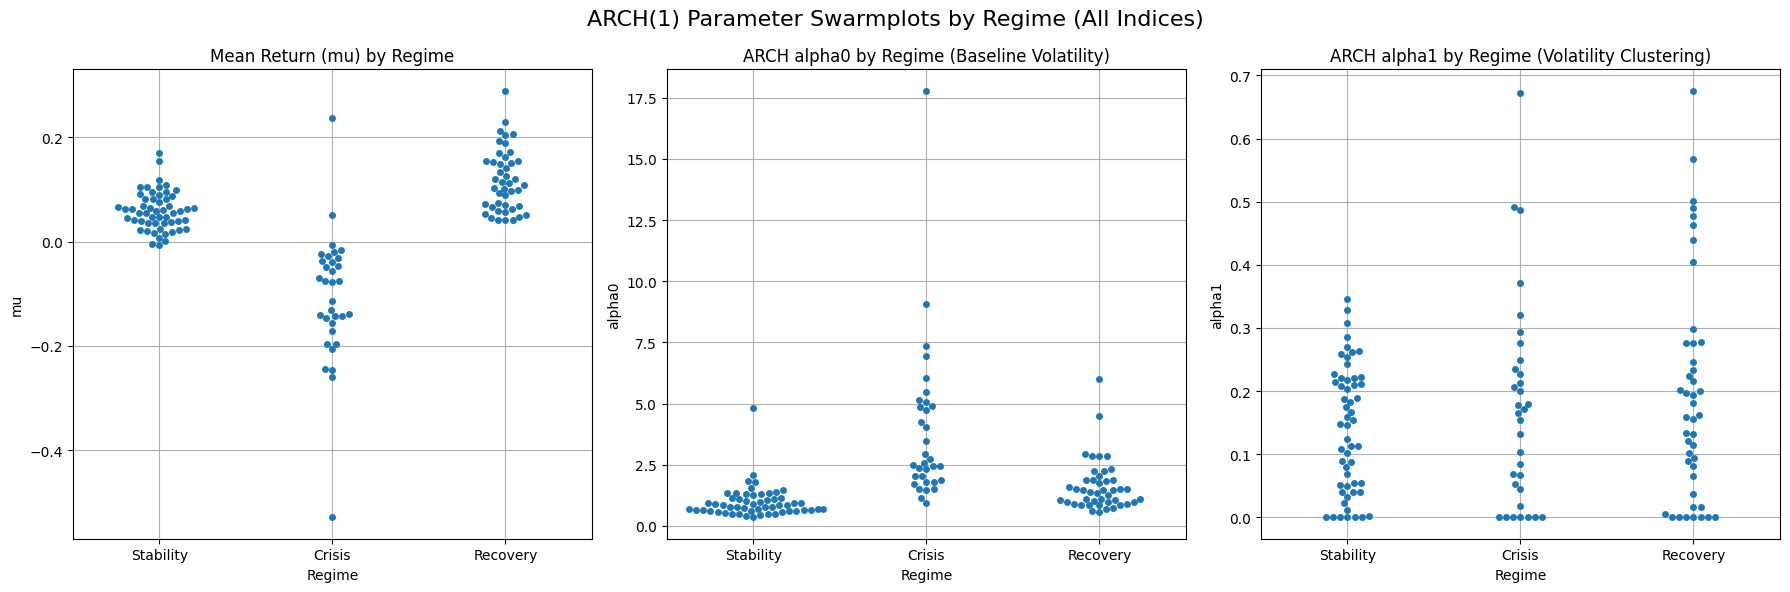

In [132]:

# Fit ARCH(1) to all indices in the SPX sectors file
results_df = fit_arch1_all_indices("spx_sectors.xlsx", regime_periods)

# Analyze and visualize results
stats_df = analyze_arch_parameters_by_regime_swarm(results_df)

✅ S5CONS — Stability — α₁: 0.0576, β₁: 0.9345
✅ S5CONS — Crisis — α₁: 0.1086, β₁: 0.8595
✅ S5CONS — Recovery — α₁: 0.0259, β₁: 0.9612
✅ S5CONS — Stability — α₁: 0.0555, β₁: 0.8527
✅ S5CONS — Crisis — α₁: 0.1490, β₁: 0.8449
✅ S5CONS — Recovery — α₁: 0.0757, β₁: 0.8878
✅ S5CONS — Stability — α₁: 0.1655, β₁: 0.7630
⚠️ Skipping S5CONS – Crisis (2020-02-18–2020-03-24): too few returns (26)
✅ S5CONS — Recovery — α₁: 0.0087, β₁: 0.9582
✅ S5CONS — Stability — α₁: 0.0913, β₁: 0.7496
✅ S5CONS — Crisis — α₁: 0.0000, β₁: 0.9755
✅ S5CONS — Recovery — α₁: 0.0000, β₁: 0.9832
✅ S5CONS — Stability — α₁: 0.0191, β₁: 0.7177
⚠️ Skipping S5CONS – Stability (2025-01-01–2025-02-20): too few returns (34)
⚠️ Skipping S5CONS – Crisis (2025-02-20–2025-04-07): too few returns (33)
⚠️ Skipping S5CONS – Recovery (2025-04-08–2025-06-18): too few returns (50)
✅ S5ENRS — Stability — α₁: 0.0315, β₁: 0.9666
✅ S5ENRS — Crisis — α₁: 0.0830, β₁: 0.8567
✅ S5ENRS — Recovery — α₁: 0.0000, β₁: 0.9789
✅ S5ENRS — Stability — α₁:

mu               omega              alpha1            \
               mean       std      mean       std      mean       std   
Regime                                                                  
Crisis    -0.066453  0.092531  0.164943  0.160006  0.081068  0.050233   
Recovery   0.110082  0.049107  0.033910  0.046739  0.046015  0.054981   
Stability  0.067477  0.035031  0.101651  0.145143  0.088777  0.061811   

              beta1           persistence            
               mean       std        mean       std  
Regime                                               
Crisis     0.877574  0.063261    0.958642  0.040792  
Recovery   0.927811  0.075930    0.973826  0.026496  
Stability  0.805906  0.197599    0.894683  0.159826

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

13.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

13.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

11.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning:

9.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.



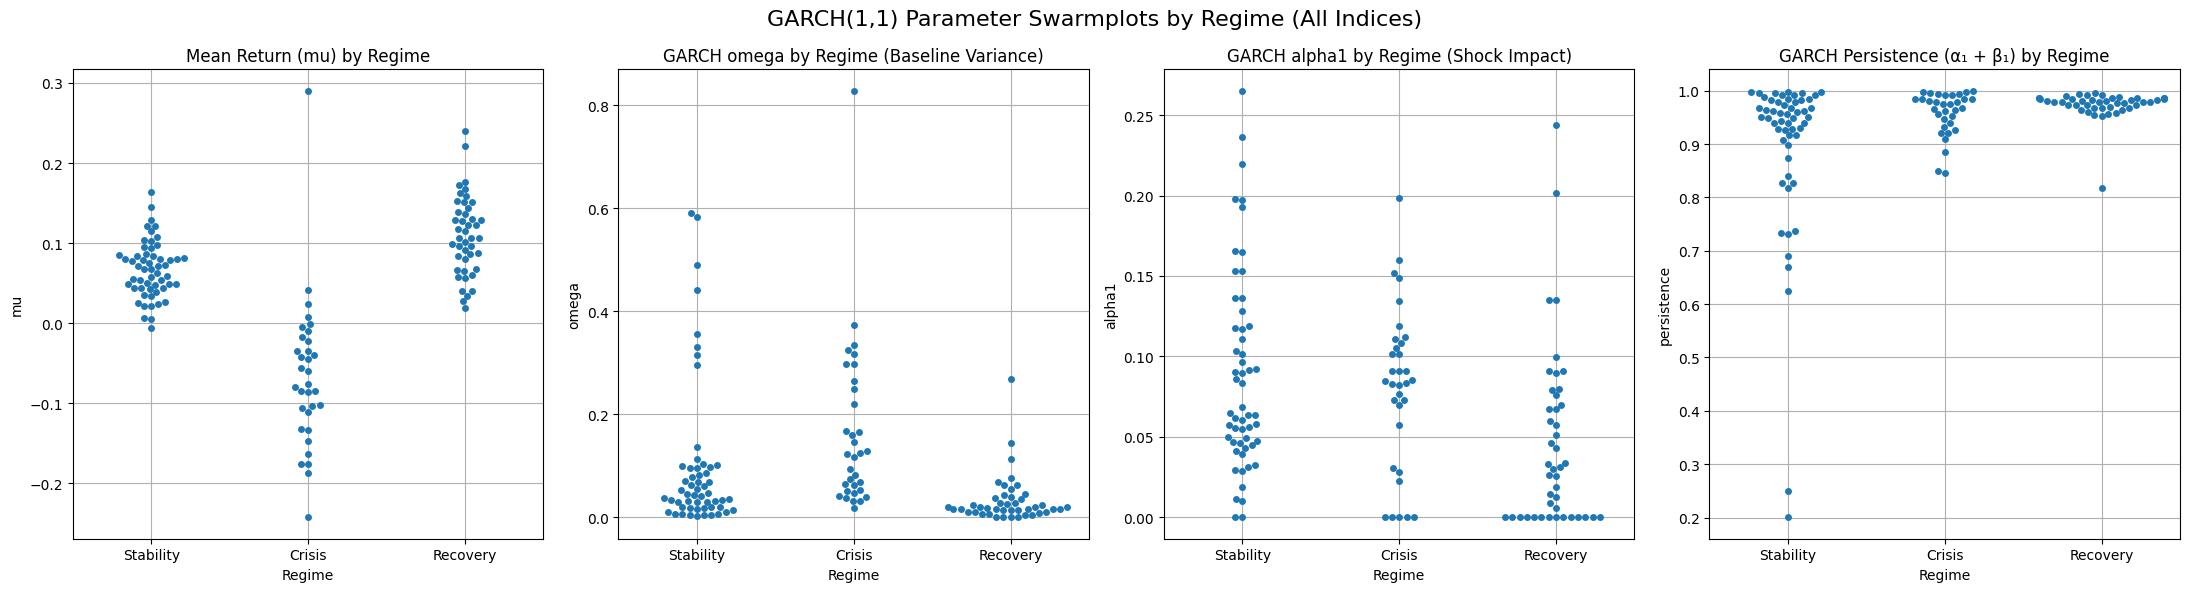

In [131]:

garch_results = fit_garch_all_indices("spx_sectors.xlsx", regime_periods)
garch_stats = plot_garch_parameter_distributions_swarm(garch_results)


In [68]:
import importlib
import functions_jules
importlib.reload(functions_jules)

from functions_jules import *  # this re-imports the updated names into the namespace


# 🧪 Étude du LASSO dans un modèle ARCH-X et plan pour le modèle MS-ARCH-X

---

## ✅ Ce qui est fait

1. **Objectif initial** : tester la capacité du LASSO à identifier les bonnes variables exogènes dans un modèle de volatilité simulé.

2. **Méthodologie :**
   - Génération de 10 variables exogènes AR(1), dont **2 uniquement** influencent la volatilité conditionnelle.
   - Simulation d’un modèle **ARCH(1)-X** :
     \[
     \sigma_t^2 = \omega + \alpha r_{t-1}^2 + \sum_{j=1}^{10} \gamma_j X_{j,t}
     \]
     avec \(\gamma_j = 0\) sauf pour 2 variables.
   - Simulation des rendements \(r_t \sim \mathcal{N}(0, \sigma_t^2)\)
   - Application de `lasso_path` (sklearn) pour balayer différentes valeurs de \(\lambda\) et identifier les deux variables les plus pertinentes.
   - Répétition de cette expérience sur plusieurs essais pour calculer un **taux de réussite**.

---

## 🧠 Compréhensions

### ❌ Limites de la méthode actuelle (LASSO + ARCH-X)

- `lasso_path` ne s’applique **que dans un cadre de régression linéaire** — il est adapté à ARCH-X mais **pas** à MS-ARCH-X, qui est un modèle **non-linéaire avec états cachés**.

- Il est **interdit de figer des coefficients à 0** (faire de la sélection de variables) en se basant sur :
  - Une estimation Viterbi faite **sans exogènes** produit une classification biaisée :
    - Le chemin \(S_t\) estimé par Viterbi repose sur un modèle **réduit**, où les variables exogènes sont absentes.
    - Or, si les exogènes influencent réellement la volatilité ou la dynamique des régimes, leur absence fausse l’estimation de la probabilité des états cachés.
    - Résultat : les observations sont **mal classées entre régimes**, ce qui induit une **mauvaise séparation des données** si on applique ensuite un LASSO dans chaque régime.
    - Une variable utile pourrait apparaître "inutile" simplement parce qu’elle agit dans un régime mal détecté.

  - Une estimation partielle (sous-modèle) — cela compromettrait toute la validité théorique.

- En revanche, on **peut utiliser LASSO pour proposer des conditions initiales**, **à condition** de laisser tous les coefficients libres ensuite pendant l'estimation complète.

---



0	Imported packages and set reproducibility
1	Defined experimental parameters and true active variables
2	Simulated AR(1) exogenous variables
3	Simulated returns using ARCH-X model
4	Built LASSO-compatible design matrix
5	Used lasso_path to find λ selecting exactly 2 exogenous variables
6	Evaluated whether the correct variables were selected
Opt.	Visualized the coefficient paths

In [43]:
result = single_lasso_trial(random_seed=76)

print("Lambda sélectionné :", result['selected_lambda'])
print("Variables choisies par LASSO :", result['selected_variables'])
print("Vrais indices actifs :", result['true_active_variables'])
print("Succès de la sélection :", "✅ Oui" if result['success'] else "❌ Non")
print("Coefficients des variables choisies :", result['selected_coefficients'])


Lambda sélectionné : 0.4563064984388813
Variables choisies par LASSO : [2 6]
Vrais indices actifs : [2, 6]
Succès de la sélection : ✅ Oui
Coefficients des variables choisies : [ 0.04059108 -0.00853253]


In [67]:
num_trials = 2000
results = []

for trial in range(num_trials):
    result = single_lasso_trial(T=5000, k=10, true_nonzero_idxs=[2, 6], gamma_vals=[0.8, 0.5], 
                       phi=0.8, omega=0.1, alpha=0.2, random_seed=None)
    results.append(result)

# Creating a DataFrame for easy analysis
df_results = pd.DataFrame(results)

# Computing accuracy
accuracy = df_results['success'].mean()
print(f"Accuracy over {num_trials} trials: {accuracy:.2%}")

# Displaying the first few results
df_results.head(40)

Accuracy over 2000 trials: 99.90%


,selected_lambda,selected_variables,selected_coefficients,true_active_variables,success
0,0.143620,"[2, 6]","[0.1034493482262023, 0.008279122619814264]","[2, 6]",True
1,0.142790,"[2, 6]","[0.06928142570573524, 0.004628349237132009]","[2, 6]",True
2,0.118611,"[2, 6]","[0.08198767791908672, 0.0030047532163136473]","[2, 6]",True
3,0.120353,"[2, 6]","[0.08230062692634983, 0.003925786774770655]","[2, 6]",True
4,0.125636,"[2, 6]","[0.06634579577252601, 0.009080187032305087]","[2, 6]",True
5,0.113756,"[2, 6]","[0.02586365427808051, 0.0038932863558393442]","[2, 6]",True
6,0.116796,"[2, 6]","[0.11530770453666865, 0.0007042727943869613]","[2, 6]",True
7,0.140030,"[2, 6]","[0.12824265071856117, 0.00908847099325292]","[2, 6]",True
8,0.117736,"[2, 6]","[0.05037123295803635, 0.002249523632653573]","[2, 6]",True
9,0.152218,"[2, 6]","[0.1322004973812717, 0.008590382898049875]","[2, 6]",True


# 📊 Analyse de l'influence de la taille d'échantillon (T) sur la performance du LASSO dans un modèle ARCH-X

---

## 🎯 Objectif

Évaluer comment le **nombre de points temporels (T)** dans la simulation affecte la **capacité du LASSO à sélectionner correctement** les deux vraies variables exogènes dans un modèle ARCH-X.

---

## ⚙️ Méthodologie

1. On fixe :
   - \(k = 10\) variables exogènes AR(1)
   - Deux d'entre elles influencent réellement la volatilité conditionnelle \(\sigma_t^2\)
   - Coefficients : par défaut [0.8, -0.5]
   - Modèle : ARCH(1)-X avec \(\sigma_t^2 = \omega + \alpha r_{t-1}^2 + \sum \gamma_j X_{j,t}\)

2. Pour chaque valeur de \(T\) dans l’intervalle \([500, 10000]\) avec un pas de 100 :
   - On répète **1000 essais** indépendants avec `single_lasso_trial`.
   - Pour chaque essai, on enregistre si LASSO a sélectionné exactement les deux bonnes variables.

3. On calcule le **taux de réussite** (= proportion de succès) pour chaque \(T\).

---

## 📈 Objectif final

Tracer la **courbe d’accuracy (en %) en fonction de \(T\)**  
Cela permet de visualiser à partir de quel nombre d’observations le LASSO devient **fiable pour la sélection de variables** dans ce cadre simulé.

---


Testing different T values: 100%|██████████| 96/96 [15:46:01<00:00, 591.26s/it]   


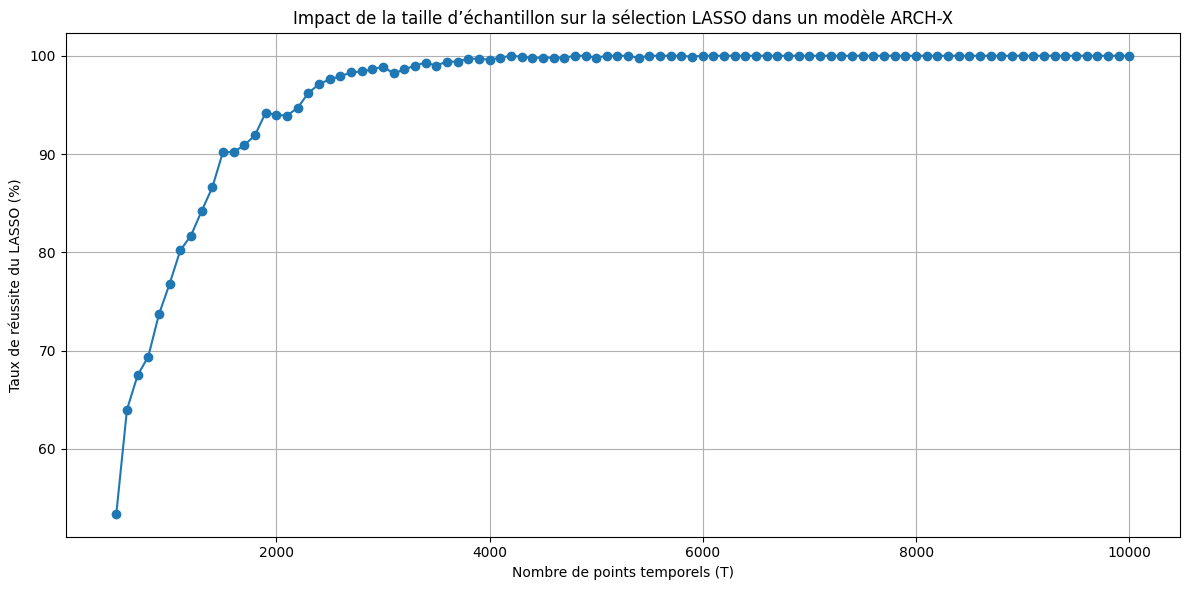

In [69]:
# Range of T to evaluate
T_values = list(range(500, 10001, 100))  # T from 500 to 10,000 by 100
num_trials = 1000                        # Number of repetitions per T
accuracy_by_T = []                       # Store success rates

# Run experiment
for T in tqdm(T_values, desc="Testing different T values"):
    success_count = 0
    for trial in range(num_trials):
        result = single_lasso_trial(T=T, random_seed=trial)
        success_count += int(result["success"])
    accuracy = success_count / num_trials
    accuracy_by_T.append(accuracy)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(T_values, [100 * acc for acc in accuracy_by_T], marker='o')
plt.xlabel("Nombre de points temporels (T)")
plt.ylabel("Taux de réussite du LASSO (%)")
plt.title("Impact de la taille d’échantillon sur la sélection LASSO dans un modèle ARCH-X")
plt.grid(True)
plt.tight_layout()
plt.show()


## 🧭 A faire
### ✅ Deux options valides pour passer à MS-ARCH-X

#### **Option 1: Initialisation via `get_initial_conditions` (recommandée)**

- Appeler `get_initial_conditions(eps, initial_params, d=2, q=1)`
- Passer les variables exogènes (additive ou transition)
- Permet d’estimer une version simplifiée du modèle (MS-ARCH-X ou MS-ARCH sans X) pour en déduire des bons paramètres de départ.

✅ Avantages :
- Théoriquement fondé
- Flexible
- Compatible avec la fonction `calibrate_and_store`

---

#### **Option 2: MS-ARCH simple + zéro-padding des exogènes**

- Estimer un MS-ARCH sans exogènes.
- Copier les paramètres estimés et ajouter des coefficients exogènes initialisés à 0.
- Utiliser ce vecteur comme point de départ pour une estimation complète MS-ARCH-X.

✅ Avantages :
- Simple, rapide, sans biais de sélection
- Permet de garder les propriétés théoriques du modèle

---

## 🛠️ Prochaine étape

➡️ Implémenter proprement l’appel à `get_initial_conditions` avec des données simulées (ou réelles), en spécifiant les champs nécessaires :
- `'exogen_additive'` pour la vol
- `'exogen_transition'` pour la matrice de transition

Et lancer une première estimation EM avec MS-ARCH-X complet sans effectuer de sélection stricte. On peut utiliser des exogènes AR(1), attention au nombre d'exo, et peut être commencer avec des exo que transitives / additives.
